<a href="https://colab.research.google.com/github/samyakjain31773-debug/-Amazon-Product-Analytics-ML-Intelligence/blob/main/Movie_Recommendation_System.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install -q pandas numpy matplotlib seaborn scikit-learn scipy

In [2]:
import os
import zipfile
import urllib.request
import warnings

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

warnings.filterwarnings("ignore")

# Visualization settings
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["figure.dpi"] = 100

# Random seed for reproducibility
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
DATA_DIR = Path("/content/movie_recommendation/data")
DATA_DIR.mkdir(parents=True, exist_ok=True)

DATASET_URL = (
    "https://files.grouplens.org/datasets/movielens/ml-1m.zip"
)

ZIP_PATH = "/content/ml-1m.zip"

# Download
urllib.request.urlretrieve(DATASET_URL, ZIP_PATH)

# Extract
with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:
    zip_ref.extractall("/content/movie_recommendation/")

print("Dataset downloaded and extracted successfully!")

Dataset downloaded and extracted successfully!


In [4]:
DATASET_FOLDER = Path("/content/movie_recommendation/ml-1m")

for file in DATASET_FOLDER.iterdir():
    print(file.name, "-", round(file.stat().st_size / 1024, 2), "KB")

movies.dat - 167.29 KB
ratings.dat - 24017.71 KB
README - 5.45 KB
users.dat - 131.22 KB


In [5]:
movie_columns = [
    "movie_id",
    "title",
    "genres"
]

movies = pd.read_csv(
    DATASET_FOLDER / "movies.dat",
    sep="::",
    engine="python",
    encoding="latin-1",
    header=None,
    names=movie_columns
)

movies.head()

,movie_id,title,genres
0,1,Toy Story (1995),Animation|Children's|Comedy
1,2,Jumanji (1995),Adventure|Children's|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama
4,5,Father of the Bride Part II (1995),Comedy


In [6]:
rating_columns = [
    "user_id",
    "movie_id",
    "rating",
    "timestamp"
]

ratings = pd.read_csv(
    DATASET_FOLDER / "ratings.dat",
    sep="::",
    engine="python",
    header=None,
    names=rating_columns
)

ratings.head()

,user_id,movie_id,rating,timestamp
0,1,1193,5,978300760
1,1,661,3,978302109
2,1,914,3,978301968
3,1,3408,4,978300275
4,1,2355,5,978824291


In [8]:
user_columns = [
    "user_id",
    "gender",
    "age",
    "occupation",
    "zip_code"
]

users = pd.read_csv(
    DATASET_FOLDER / "users.dat",
    sep="::",
    engine="python",
    header=None,
    names=user_columns
)

users.head()

,user_id,gender,age,occupation,zip_code
0,1,F,1,10,48067
1,2,M,56,16,70072
2,3,M,25,15,55117
3,4,M,45,7,02460
4,5,M,25,20,55455


In [9]:
print("MOVIES SHAPE:", movies.shape)
print("RATINGS SHAPE:", ratings.shape)
print("USERS SHAPE:", users.shape)

MOVIES SHAPE: (3883, 3)
RATINGS SHAPE: (1000209, 4)
USERS SHAPE: (6040, 5)


In [10]:
print("\nMOVIES INFORMATION")
movies.info()

print("\nRATINGS INFORMATION")
ratings.info()

print("\nUSERS INFORMATION")
users.info()


MOVIES INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3883 entries, 0 to 3882
Data columns (total 3 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   movie_id  3883 non-null   int64 
 1   title     3883 non-null   object
 2   genres    3883 non-null   object
dtypes: int64(1), object(2)
memory usage: 91.1+ KB

RATINGS INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000209 entries, 0 to 1000208
Data columns (total 4 columns):
 #   Column     Non-Null Count    Dtype
---  ------     --------------    -----
 0   user_id    1000209 non-null  int64
 1   movie_id   1000209 non-null  int64
 2   rating     1000209 non-null  int64
 3   timestamp  1000209 non-null  int64
dtypes: int64(4)
memory usage: 30.5 MB

USERS INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6040 entries, 0 to 6039
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id    

In [11]:
print("MOVIE DATA")
display(movies.describe(include="all"))

print("RATING DATA")
display(ratings.describe())

print("USER DATA")
display(users.describe(include="all"))

MOVIE DATA


,movie_id,title,genres
count,3883.000000,3883,3883
unique,NaN,3883,301
top,NaN,Toy Story (1995),Drama
freq,NaN,1,843
mean,1986.049446,NaN,NaN
std,1146.778349,NaN,NaN
min,1.000000,NaN,NaN
25%,982.500000,NaN,NaN
50%,2010.000000,NaN,NaN
75%,2980.500000,NaN,NaN


RATING DATA


,user_id,movie_id,rating,timestamp
count,1.000209e+06,1.000209e+06,1.000209e+06,1.000209e+06
mean,3.024512e+03,1.865540e+03,3.581564e+00,9.722437e+08
std,1.728413e+03,1.096041e+03,1.117102e+00,1.215256e+07
min,1.000000e+00,1.000000e+00,1.000000e+00,9.567039e+08
25%,1.506000e+03,1.030000e+03,3.000000e+00,9.653026e+08
50%,3.070000e+03,1.835000e+03,4.000000e+00,9.730180e+08
75%,4.476000e+03,2.770000e+03,4.000000e+00,9.752209e+08
max,6.040000e+03,3.952000e+03,5.000000e+00,1.046455e+09


USER DATA


,user_id,gender,age,occupation,zip_code
count,6040.000000,6040,6040.000000,6040.000000,6040
unique,NaN,2,NaN,NaN,3439
top,NaN,M,NaN,NaN,48104
freq,NaN,4331,NaN,NaN,19
mean,3020.500000,NaN,30.639238,8.146854,NaN
std,1743.742145,NaN,12.895962,6.329511,NaN
min,1.000000,NaN,1.000000,0.000000,NaN
25%,1510.750000,NaN,25.000000,3.000000,NaN
50%,3020.500000,NaN,25.000000,7.000000,NaN
75%,4530.250000,NaN,35.000000,14.000000,NaN


In [12]:
def missing_value_report(df, name):
    report = pd.DataFrame({
        "Missing_Count": df.isnull().sum(),
        "Missing_Percentage": (
            df.isnull().mean() * 100
        ).round(2)
    })

    print(f"\n{name} Missing Value Report")
    display(report)

missing_value_report(movies, "Movies")
missing_value_report(ratings, "Ratings")
missing_value_report(users, "Users")


Movies Missing Value Report


,Missing_Count,Missing_Percentage
movie_id,0,0.0
title,0,0.0
genres,0,0.0



Ratings Missing Value Report


,Missing_Count,Missing_Percentage
user_id,0,0.0
movie_id,0,0.0
rating,0,0.0
timestamp,0,0.0



Users Missing Value Report


,Missing_Count,Missing_Percentage
user_id,0,0.0
gender,0,0.0
age,0,0.0
occupation,0,0.0
zip_code,0,0.0


In [13]:
print("Movies duplicate rows:", movies.duplicated().sum())

print("Ratings duplicate rows:", ratings.duplicated().sum())

print("Users duplicate rows:", users.duplicated().sum())

# Check duplicate user-movie combinations
print(
    "Duplicate user-movie pairs:",
    ratings.duplicated(
        subset=["user_id", "movie_id"]
    ).sum()
)

Movies duplicate rows: 0
Ratings duplicate rows: 0
Users duplicate rows: 0
Duplicate user-movie pairs: 0


In [14]:
print("Minimum rating:", ratings["rating"].min())
print("Maximum rating:", ratings["rating"].max())

print("\nRating frequencies:")
display(ratings["rating"].value_counts().sort_index())

invalid_ratings = ratings[
    ~ratings["rating"].between(1, 5)
]

print("Invalid ratings:", len(invalid_ratings))

Minimum rating: 1
Maximum rating: 5

Rating frequencies:


,count
rating,
1,56174
2,107557
3,261197
4,348971
5,226310


Invalid ratings: 0


In [15]:
print(
    "Ratings without matching movies:",
    (~ratings["movie_id"].isin(movies["movie_id"])).sum()
)

print(
    "Ratings without matching users:",
    (~ratings["user_id"].isin(users["user_id"])).sum()
)

print(
    "Movies without ratings:",
    (~movies["movie_id"].isin(ratings["movie_id"])).sum()
)

Ratings without matching movies: 0
Ratings without matching users: 0
Movies without ratings: 177


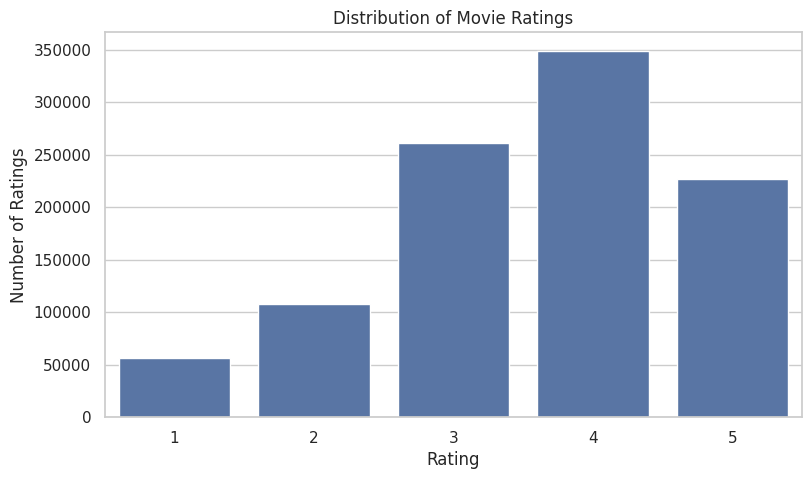

In [16]:
rating_counts = ratings["rating"].value_counts().sort_index()

plt.figure(figsize=(9, 5))

sns.barplot(
    x=rating_counts.index,
    y=rating_counts.values
)

plt.title("Distribution of Movie Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of Ratings")

plt.show()

In [17]:
movie_stats = ratings.groupby("movie_id").agg(
    rating_count=("rating", "count"),
    average_rating=("rating", "mean")
).reset_index()

movie_stats = movie_stats.merge(
    movies,
    on="movie_id",
    how="left"
)

top_popular = movie_stats.sort_values(
    "rating_count",
    ascending=False
).head(15)

display(
    top_popular[
        ["title", "rating_count", "average_rating"]
    ]
)

,title,rating_count,average_rating
2651,American Beauty (1999),3428,4.317386
253,Star Wars: Episode IV - A New Hope (1977),2991,4.453694
1106,Star Wars: Episode V - The Empire Strikes Back...,2990,4.292977
1120,Star Wars: Episode VI - Return of the Jedi (1983),2883,4.022893
466,Jurassic Park (1993),2672,3.763847
1848,Saving Private Ryan (1998),2653,4.337354
575,Terminator 2: Judgment Day (1991),2649,4.058513
2374,"Matrix, The (1999)",2590,4.315830
1178,Back to the Future (1985),2583,3.990321
579,"Silence of the Lambs, The (1991)",2578,4.351823


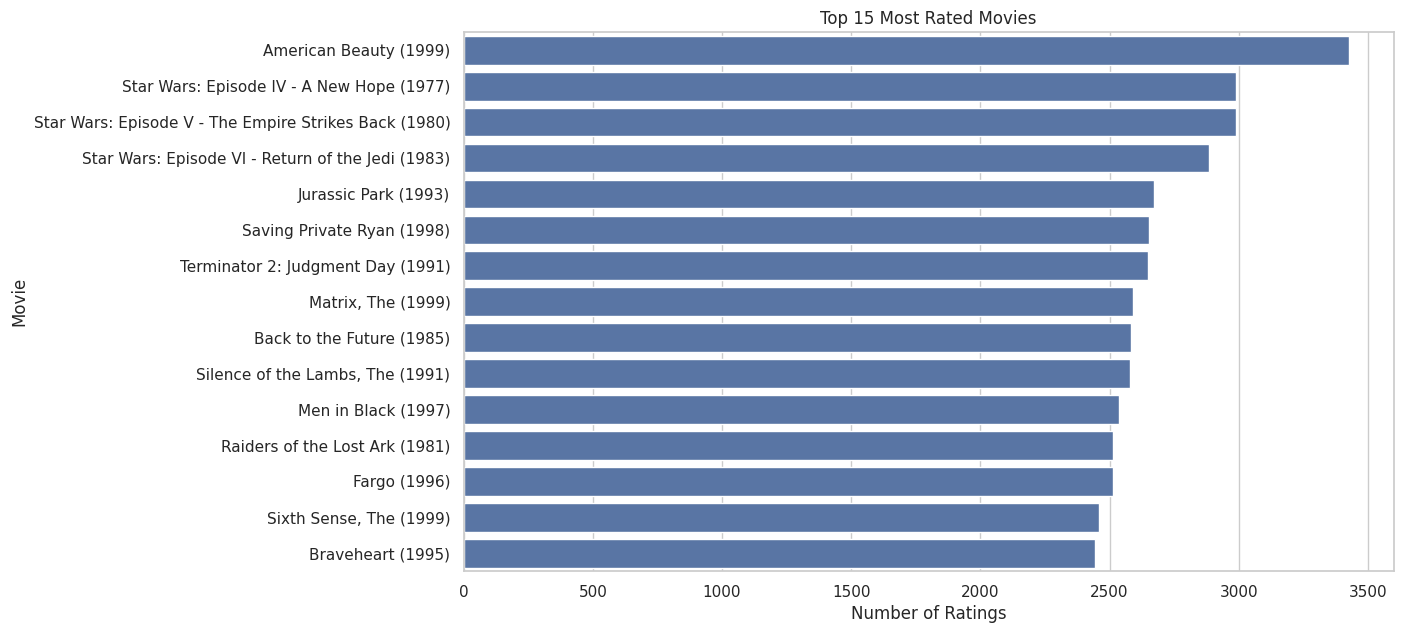

In [18]:
plt.figure(figsize=(12, 7))

sns.barplot(
    data=top_popular,
    x="rating_count",
    y="title"
)

plt.title("Top 15 Most Rated Movies")
plt.xlabel("Number of Ratings")
plt.ylabel("Movie")

plt.show()

In [19]:
genre_data = movies.copy()

genre_data["genres"] = genre_data["genres"].str.split("|")

genre_exploded = genre_data.explode("genres")

genre_counts = genre_exploded["genres"].value_counts()

display(genre_counts.to_frame("movie_count"))

,movie_count
genres,
Drama,1603
Comedy,1200
Action,503
Thriller,492
Romance,471
Horror,343
Adventure,283
Sci-Fi,276
Children's,251


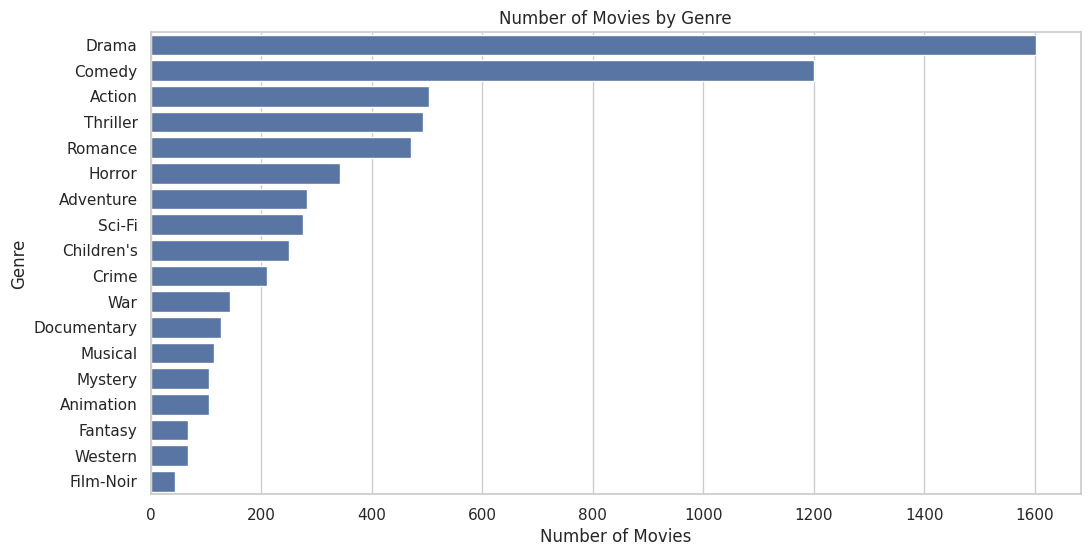

In [20]:
plt.figure(figsize=(12, 6))

sns.barplot(
    x=genre_counts.values,
    y=genre_counts.index
)

plt.title("Number of Movies by Genre")
plt.xlabel("Number of Movies")
plt.ylabel("Genre")

plt.show()

In [21]:
rating_genres = ratings.merge(
    movies[["movie_id", "genres"]],
    on="movie_id",
    how="inner"
)

rating_genres["genres"] = (
    rating_genres["genres"].str.split("|")
)

rating_genres = rating_genres.explode("genres")

genre_ratings = rating_genres.groupby("genres").agg(
    average_rating=("rating", "mean"),
    total_ratings=("rating", "count")
).sort_values(
    "average_rating",
    ascending=False
)

display(genre_ratings)

,average_rating,total_ratings
genres,,
Film-Noir,4.075188,18261
Documentary,3.933123,7910
War,3.893327,68527
Drama,3.766332,354529
Crime,3.708679,79541
Animation,3.684868,43293
Mystery,3.668102,40178
Musical,3.665519,41533
Western,3.637770,20683


In [22]:
user_activity = ratings.groupby("user_id").agg(
    total_ratings=("rating", "count"),
    average_rating=("rating", "mean")
)

print(user_activity.describe())

       total_ratings  average_rating
count    6040.000000     6040.000000
mean      165.597517        3.702705
std       192.747029        0.429622
min        20.000000        1.015385
25%        44.000000        3.444444
50%        96.000000        3.735294
75%       208.000000        4.000000
max      2314.000000        4.962963


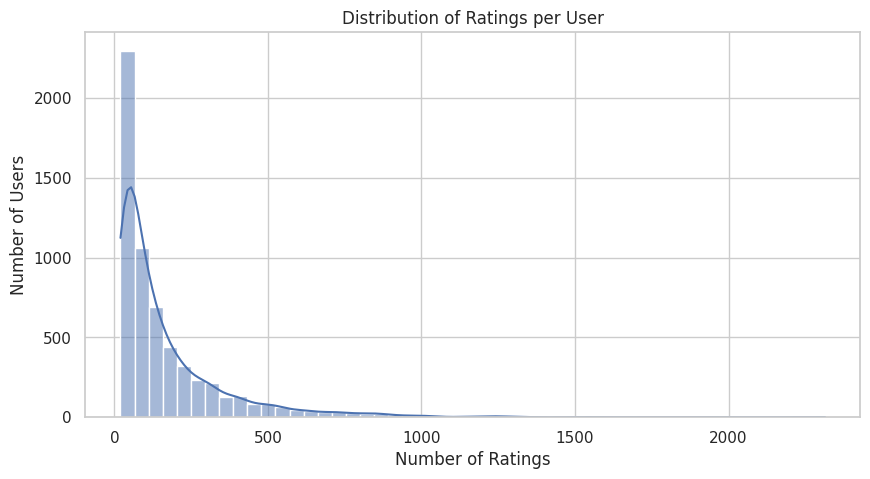

In [23]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=user_activity,
    x="total_ratings",
    bins=50,
    kde=True
)

plt.title("Distribution of Ratings per User")
plt.xlabel("Number of Ratings")
plt.ylabel("Number of Users")

plt.show()

In [24]:
ratings["rating_date"] = pd.to_datetime(
    ratings["timestamp"],
    unit="s"
)

ratings["rating_year"] = ratings["rating_date"].dt.year

yearly_activity = ratings.groupby("rating_year").size()

display(yearly_activity.to_frame("total_ratings"))

,total_ratings
rating_year,
2000,904757
2001,68058
2002,24046
2003,3348


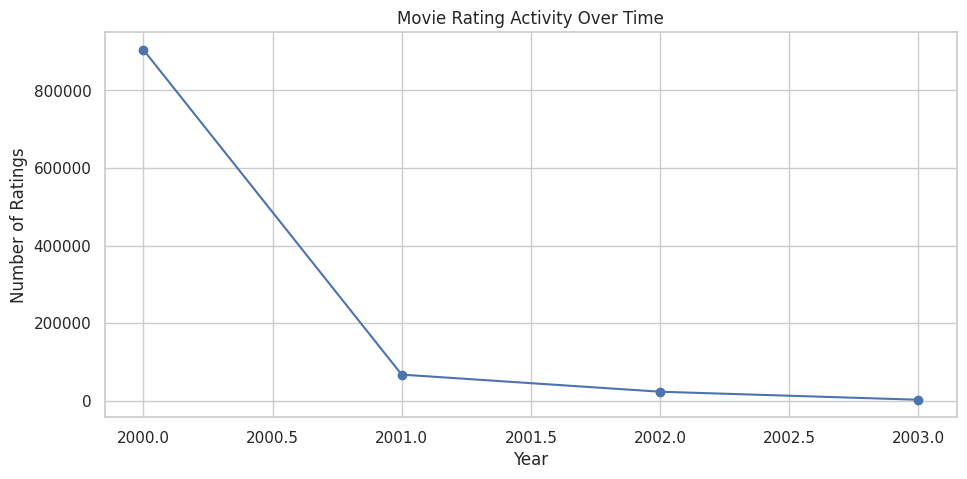

In [25]:
plt.figure(figsize=(11, 5))

yearly_activity.plot(kind="line", marker="o")

plt.title("Movie Rating Activity Over Time")
plt.xlabel("Year")
plt.ylabel("Number of Ratings")

plt.show()

In [26]:
df = ratings.merge(
    movies,
    on="movie_id",
    how="inner"
)

print("Final dataset shape:", df.shape)

display(df.head())

Final dataset shape: (1000209, 8)


,user_id,movie_id,rating,timestamp,rating_date,rating_year,title,genres
0,1,1193,5,978300760,2000-12-31 22:12:40,2000,One Flew Over the Cuckoo's Nest (1975),Drama
1,1,661,3,978302109,2000-12-31 22:35:09,2000,James and the Giant Peach (1996),Animation|Children's|Musical
2,1,914,3,978301968,2000-12-31 22:32:48,2000,My Fair Lady (1964),Musical|Romance
3,1,3408,4,978300275,2000-12-31 22:04:35,2000,Erin Brockovich (2000),Drama
4,1,2355,5,978824291,2001-01-06 23:38:11,2001,"Bug's Life, A (1998)",Animation|Children's|Comedy


In [27]:
print("Final dataset information:")
print(df.info())

print("\nMissing values:")
display(df.isnull().sum())

print("\nUnique users:", df["user_id"].nunique())
print("Unique movies:", df["movie_id"].nunique())
print("Total ratings:", len(df))

print("\nRating range:")
print(df["rating"].min(), "to", df["rating"].max())

Final dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000209 entries, 0 to 1000208
Data columns (total 8 columns):
 #   Column       Non-Null Count    Dtype         
---  ------       --------------    -----         
 0   user_id      1000209 non-null  int64         
 1   movie_id     1000209 non-null  int64         
 2   rating       1000209 non-null  int64         
 3   timestamp    1000209 non-null  int64         
 4   rating_date  1000209 non-null  datetime64[ns]
 5   rating_year  1000209 non-null  int32         
 6   title        1000209 non-null  object        
 7   genres       1000209 non-null  object        
dtypes: datetime64[ns](1), int32(1), int64(4), object(2)
memory usage: 57.2+ MB
None

Missing values:


,0
user_id,0
movie_id,0
rating,0
timestamp,0
rating_date,0
rating_year,0
title,0
genres,0



Unique users: 6040
Unique movies: 3706
Total ratings: 1000209

Rating range:
1 to 5


In [28]:
OUTPUT_DIR = Path("/content/movie_recommendation/processed")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

movies.to_csv(
    OUTPUT_DIR / "movies.csv",
    index=False
)

ratings.to_csv(
    OUTPUT_DIR / "ratings.csv",
    index=False
)

users.to_csv(
    OUTPUT_DIR / "users.csv",
    index=False
)

df.to_csv(
    OUTPUT_DIR / "master_dataset.csv",
    index=False
)

print("Processed datasets saved successfully!")

Processed datasets saved successfully!


In [29]:
print("=" * 55)
print("MOVIE RECOMMENDATION SYSTEM - DATA AUDIT")
print("=" * 55)

# 1. Duplicate records
print("\n1. DUPLICATE RECORDS")

print("Duplicate movies:",
      movies.duplicated().sum())

print("Duplicate ratings:",
      ratings.duplicated().sum())

print("Duplicate users:",
      users.duplicated().sum())

print("Duplicate user-movie pairs:",
      ratings.duplicated(
          subset=["user_id", "movie_id"]
      ).sum())


# 2. ID consistency
print("\n2. ID CONSISTENCY")

print("Unmatched movie IDs:",
      (~ratings.movie_id.isin(movies.movie_id)).sum())

print("Unmatched user IDs:",
      (~ratings.user_id.isin(users.user_id)).sum())


# 3. Unrated movies
print("\n3. UNRATED MOVIES")

unrated_movies = movies[
    ~movies.movie_id.isin(ratings.movie_id)
]

print("Unrated movie count:", len(unrated_movies))


# 4. Rating distribution
print("\n4. RATING DISTRIBUTION")

print(ratings.rating.value_counts().sort_index())


# 5. User activity
print("\n5. USER ACTIVITY")

user_counts = ratings.groupby("user_id").size()

print("Minimum ratings per user:", user_counts.min())
print("Maximum ratings per user:", user_counts.max())
print("Average ratings per user:", round(user_counts.mean(), 2))


# 6. Movie activity
print("\n6. MOVIE ACTIVITY")

movie_counts = ratings.groupby("movie_id").size()

print("Minimum ratings per movie:", movie_counts.min())
print("Maximum ratings per movie:", movie_counts.max())
print("Average ratings per rated movie:",
      round(movie_counts.mean(), 2))


print("\nAUDIT COMPLETED")

MOVIE RECOMMENDATION SYSTEM - DATA AUDIT

1. DUPLICATE RECORDS
Duplicate movies: 0
Duplicate ratings: 0
Duplicate users: 0
Duplicate user-movie pairs: 0

2. ID CONSISTENCY
Unmatched movie IDs: 0
Unmatched user IDs: 0

3. UNRATED MOVIES
Unrated movie count: 177

4. RATING DISTRIBUTION
rating
1     56174
2    107557
3    261197
4    348971
5    226310
Name: count, dtype: int64

5. USER ACTIVITY
Minimum ratings per user: 20
Maximum ratings per user: 2314
Average ratings per user: 165.6

6. MOVIE ACTIVITY
Minimum ratings per movie: 1
Maximum ratings per movie: 3428
Average ratings per rated movie: 269.89

AUDIT COMPLETED


In [30]:
# Keep all movies, not only rated movies
content_movies = movies.copy()

# Check original data
print("Original shape:", content_movies.shape)

# Clean genres
content_movies["genres"] = (
    content_movies["genres"]
    .fillna("")
    .str.replace("|", " ", regex=False)
    .str.strip()
)

# Remove movies without genre information
content_movies = content_movies[
    content_movies["genres"] != ""
].reset_index(drop=True)

print("Processed shape:", content_movies.shape)

display(content_movies.head(10))

Original shape: (3883, 3)
Processed shape: (3883, 3)


,movie_id,title,genres
0,1,Toy Story (1995),Animation Children's Comedy
1,2,Jumanji (1995),Adventure Children's Fantasy
2,3,Grumpier Old Men (1995),Comedy Romance
3,4,Waiting to Exhale (1995),Comedy Drama
4,5,Father of the Bride Part II (1995),Comedy
5,6,Heat (1995),Action Crime Thriller
6,7,Sabrina (1995),Comedy Romance
7,8,Tom and Huck (1995),Adventure Children's
8,9,Sudden Death (1995),Action
9,10,GoldenEye (1995),Action Adventure Thriller


In [31]:
print("Unique genres:")
all_genres = sorted(
    set(
        genre
        for genres in movies["genres"]
        for genre in genres.split("|")
    )
)

print(all_genres)
print("\nTotal unique genres:", len(all_genres))

Unique genres:
['Action', 'Adventure', 'Animation', "Children's", 'Comedy', 'Crime', 'Documentary', 'Drama', 'Fantasy', 'Film-Noir', 'Horror', 'Musical', 'Mystery', 'Romance', 'Sci-Fi', 'Thriller', 'War', 'Western']

Total unique genres: 18


In [32]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    lowercase=True,
    token_pattern=r"(?u)\b[\w'-]+\b",
    norm="l2"
)

tfidf_matrix = tfidf.fit_transform(
    content_movies["genres"]
)

print("TF-IDF matrix shape:", tfidf_matrix.shape)
print("Number of features:", len(tfidf.get_feature_names_out()))
print("Matrix type:", type(tfidf_matrix))

TF-IDF matrix shape: (3883, 18)
Number of features: 18
Matrix type: <class 'scipy.sparse._csr.csr_matrix'>


In [33]:
feature_names = tfidf.get_feature_names_out()

print("TF-IDF vocabulary:")
print(feature_names)

TF-IDF vocabulary:
['action' 'adventure' 'animation' "children's" 'comedy' 'crime'
 'documentary' 'drama' 'fantasy' 'film-noir' 'horror' 'musical' 'mystery'
 'romance' 'sci-fi' 'thriller' 'war' 'western']


In [34]:
tfidf_df = pd.DataFrame(
    tfidf_matrix[:5].toarray(),
    columns=feature_names
)

display(tfidf_df.round(3))

,action,adventure,animation,children's,comedy,crime,documentary,drama,fantasy,film-noir,horror,musical,mystery,romance,sci-fi,thriller,war,western
0,0.0,0.0,0.729,0.592,0.344,0.0,0.0,0.000,0.000,0.0,0.0,0.0,0.0,0.000,0.0,0.0,0.0,0.0
1,0.0,0.5,0.000,0.516,0.000,0.0,0.0,0.000,0.695,0.0,0.0,0.0,0.0,0.000,0.0,0.0,0.0,0.0
2,0.0,0.0,0.000,0.000,0.573,0.0,0.0,0.000,0.000,0.0,0.0,0.0,0.0,0.819,0.0,0.0,0.0,0.0
3,0.0,0.0,0.000,0.000,0.756,0.0,0.0,0.655,0.000,0.0,0.0,0.0,0.0,0.000,0.0,0.0,0.0,0.0
4,0.0,0.0,0.000,0.000,1.000,0.0,0.0,0.000,0.000,0.0,0.0,0.0,0.0,0.000,0.0,0.0,0.0,0.0


In [35]:
from sklearn.metrics.pairwise import linear_kernel

print("Cosine similarity can be calculated using linear_kernel.")

Cosine similarity can be calculated using linear_kernel.


In [36]:
# Map each movie title to its row index
movie_indices = pd.Series(
    content_movies.index,
    index=content_movies["title"]
)

print("Movie index created successfully!")
print(movie_indices.head())

Movie index created successfully!
title
Toy Story (1995)                      0
Jumanji (1995)                        1
Grumpier Old Men (1995)               2
Waiting to Exhale (1995)              3
Father of the Bride Part II (1995)    4
dtype: int64


In [38]:
def recommend_movies(movie_title, n_recommendations=10):

    # Check whether movie exists
    if movie_title not in movie_indices.index:
        print(f"Movie not found: {movie_title}")
        return None

    # Get movie index
    idx = movie_indices[movie_title]

    # Calculate similarity against all movies
    similarity_scores = linear_kernel(
        tfidf_matrix[idx],
        tfidf_matrix
    ).flatten()

    # Sort movies by similarity
    similar_indices = np.argsort(
        similarity_scores
    )[::-1]

    # Exclude the input movie itself
    similar_indices = [
        i for i in similar_indices
        if i != idx
    ]

    # Select top N recommendations
    top_indices = similar_indices[:n_recommendations]

    # Prepare output
    recommendations = content_movies.iloc[
        top_indices
    ][["movie_id", "title", "genres"]].copy()

    recommendations["similarity_score"] = [
        similarity_scores[i] for i in top_indices
    ]

    recommendations.reset_index(drop=True, inplace=True)

    return recommendations

In [39]:
recommendations = recommend_movies(
    "Toy Story (1995)",
    n_recommendations=10
)

display(recommendations)

,movie_id,title,genres,similarity_score
0,3611,Saludos Amigos (1943),Animation Children's Comedy,1.000000
1,2141,"American Tail, An (1986)",Animation Children's Comedy,1.000000
2,2354,"Rugrats Movie, The (1998)",Animation Children's Comedy,1.000000
3,2355,"Bug's Life, A (1998)",Animation Children's Comedy,1.000000
4,3114,Toy Story 2 (1999),Animation Children's Comedy,1.000000
5,2142,"American Tail: Fievel Goes West, An (1991)",Animation Children's Comedy,1.000000
6,3751,Chicken Run (2000),Animation Children's Comedy,1.000000
7,3754,"Adventures of Rocky and Bullwinkle, The (2000)",Animation Children's Comedy,1.000000
8,1064,Aladdin and the King of Thieves (1996),Animation Children's Comedy,1.000000
9,13,Balto (1995),Animation Children's,0.938841


In [40]:
test_movies = [
    "Toy Story (1995)",
    "Jurassic Park (1993)",
    "Matrix, The (1999)",
    "Titanic (1997)",
    "Terminator 2: Judgment Day (1991)"
]

for movie in test_movies:

    print("\n" + "=" * 70)
    print("INPUT MOVIE:", movie)
    print("=" * 70)

    result = recommend_movies(movie, 5)

    if result is not None:
        display(result)


INPUT MOVIE: Toy Story (1995)


,movie_id,title,genres,similarity_score
0,3611,Saludos Amigos (1943),Animation Children's Comedy,1.0
1,2141,"American Tail, An (1986)",Animation Children's Comedy,1.0
2,2354,"Rugrats Movie, The (1998)",Animation Children's Comedy,1.0
3,2355,"Bug's Life, A (1998)",Animation Children's Comedy,1.0
4,3114,Toy Story 2 (1999),Animation Children's Comedy,1.0



INPUT MOVIE: Jurassic Park (1993)


,movie_id,title,genres,similarity_score
0,316,Stargate (1994),Action Adventure Sci-Fi,1.0
1,329,Star Trek: Generations (1994),Action Adventure Sci-Fi,1.0
2,3864,Godzilla 2000 (Gojira ni-sen mireniamu) (1999),Action Adventure Sci-Fi,1.0
3,1374,Star Trek: The Wrath of Khan (1982),Action Adventure Sci-Fi,1.0
4,1375,Star Trek III: The Search for Spock (1984),Action Adventure Sci-Fi,1.0



INPUT MOVIE: Matrix, The (1999)


,movie_id,title,genres,similarity_score
0,2722,Deep Blue Sea (1999),Action Sci-Fi Thriller,1.0
1,172,Johnny Mnemonic (1995),Action Sci-Fi Thriller,1.0
2,2600,eXistenZ (1999),Action Sci-Fi Thriller,1.0
3,1037,"Lawnmower Man, The (1992)",Action Sci-Fi Thriller,1.0
4,286,Nemesis 2: Nebula (1995),Action Sci-Fi Thriller,1.0



INPUT MOVIE: Titanic (1997)


,movie_id,title,genres,similarity_score
0,1851,Leather Jacket Love Story (1997),Drama Romance,1.0
1,1850,"I Love You, Don't Touch Me! (1998)",Drama Romance,1.0
2,1043,To Gillian on Her 37th Birthday (1996),Drama Romance,1.0
3,1046,Beautiful Thing (1996),Drama Romance,1.0
4,1059,William Shakespeare's Romeo and Juliet (1996),Drama Romance,1.0



INPUT MOVIE: Terminator 2: Judgment Day (1991)


,movie_id,title,genres,similarity_score
0,2722,Deep Blue Sea (1999),Action Sci-Fi Thriller,1.0
1,172,Johnny Mnemonic (1995),Action Sci-Fi Thriller,1.0
2,2600,eXistenZ (1999),Action Sci-Fi Thriller,1.0
3,2571,"Matrix, The (1999)",Action Sci-Fi Thriller,1.0
4,1037,"Lawnmower Man, The (1992)",Action Sci-Fi Thriller,1.0


In [41]:
# Test 1: Movie exists
assert "Toy Story (1995)" in movie_indices.index

# Test 2: TF-IDF matrix has correct number of rows
assert tfidf_matrix.shape[0] == len(content_movies)

# Test 3: Similarity scores are within valid bounds
test_idx = movie_indices["Toy Story (1995)"]

scores = linear_kernel(
    tfidf_matrix[test_idx],
    tfidf_matrix
).flatten()

assert np.all(scores >= -1e-9)
assert np.all(scores <= 1 + 1e-9)

# Test 4: Movie does not recommend itself
test_result = recommend_movies("Toy Story (1995)", 10)

assert "Toy Story (1995)" not in test_result["title"].values

# Test 5: Correct number of recommendations
assert len(test_result) == 10

print("All model sanity checks passed!")

All model sanity checks passed!


In [42]:
from sklearn.preprocessing import MultiLabelBinarizer

# Convert genres into lists
genre_lists = content_movies["genres"].apply(
    lambda x: x.split()
)

# Multi-hot encoding
mlb = MultiLabelBinarizer()

genre_matrix = mlb.fit_transform(genre_lists)

print("Multi-hot matrix shape:", genre_matrix.shape)
print("Genre features:", mlb.classes_)

Multi-hot matrix shape: (3883, 18)
Genre features: ['Action' 'Adventure' 'Animation' "Children's" 'Comedy' 'Crime'
 'Documentary' 'Drama' 'Fantasy' 'Film-Noir' 'Horror' 'Musical' 'Mystery'
 'Romance' 'Sci-Fi' 'Thriller' 'War' 'Western']


In [43]:
from sklearn.metrics.pairwise import cosine_similarity

multi_hot_similarity = cosine_similarity(
    genre_matrix,
    dense_output=False
)

print("Similarity matrix:", multi_hot_similarity.shape)

Similarity matrix: (3883, 3883)


In [46]:
def recommend_movies_multihot(movie_title, n_recommendations=10):

    if movie_title not in movie_indices.index:
        print("Movie not found!")
        return None

    idx = movie_indices[movie_title]

    scores = np.asarray(multi_hot_similarity[idx]).flatten()

    similar_indices = np.argsort(scores)[::-1]

    similar_indices = [
        i for i in similar_indices if i != idx
    ]

    top_indices = similar_indices[:n_recommendations]

    result = content_movies.iloc[top_indices][
        ["movie_id", "title", "genres"]
    ].copy()

    result["similarity_score"] = scores[top_indices]

    return result.reset_index(drop=True)

In [50]:
test_movie = "Toy Story (1995)"

print("TF-IDF RECOMMENDATIONS")
display(
    recommend_movies(test_movie, 10)
)

print("MULTI-HOT RECOMMENDATIONS")
display(
    recommend_movies_multihot(test_movie, 10)
)

TF-IDF RECOMMENDATIONS


,movie_id,title,genres,similarity_score
0,3611,Saludos Amigos (1943),Animation Children's Comedy,1.000000
1,2141,"American Tail, An (1986)",Animation Children's Comedy,1.000000
2,2354,"Rugrats Movie, The (1998)",Animation Children's Comedy,1.000000
3,2355,"Bug's Life, A (1998)",Animation Children's Comedy,1.000000
4,3114,Toy Story 2 (1999),Animation Children's Comedy,1.000000
5,2142,"American Tail: Fievel Goes West, An (1991)",Animation Children's Comedy,1.000000
6,3751,Chicken Run (2000),Animation Children's Comedy,1.000000
7,3754,"Adventures of Rocky and Bullwinkle, The (2000)",Animation Children's Comedy,1.000000
8,1064,Aladdin and the King of Thieves (1996),Animation Children's Comedy,1.000000
9,13,Balto (1995),Animation Children's,0.938841


MULTI-HOT RECOMMENDATIONS


,movie_id,title,genres,similarity_score
0,2141,"American Tail, An (1986)",Animation Children's Comedy,1.000000
1,3751,Chicken Run (2000),Animation Children's Comedy,1.000000
2,3754,"Adventures of Rocky and Bullwinkle, The (2000)",Animation Children's Comedy,1.000000
3,1064,Aladdin and the King of Thieves (1996),Animation Children's Comedy,1.000000
4,3611,Saludos Amigos (1943),Animation Children's Comedy,1.000000
5,2354,"Rugrats Movie, The (1998)",Animation Children's Comedy,1.000000
6,2142,"American Tail: Fievel Goes West, An (1991)",Animation Children's Comedy,1.000000
7,3114,Toy Story 2 (1999),Animation Children's Comedy,1.000000
8,2355,"Bug's Life, A (1998)",Animation Children's Comedy,1.000000
9,2078,"Jungle Book, The (1967)",Animation Children's Comedy Musical,0.866025


In [51]:

test_movies = [
    "Toy Story (1995)",
    "Jurassic Park (1993)",
    "The Matrix (1999)",
    "Titanic (1997)",
    "Terminator 2: Judgment Day (1991)"
]

for movie in test_movies:

    print("\n" + "=" * 70)
    print("MOVIE:", movie)
    print("=" * 70)

    print("\nTF-IDF:")
    display(recommend_movies(movie, 5))

    print("\nMULTI-HOT:")
    display(recommend_movies_multihot(movie, 5))



MOVIE: Toy Story (1995)

TF-IDF:


,movie_id,title,genres,similarity_score
0,3611,Saludos Amigos (1943),Animation Children's Comedy,1.0
1,2141,"American Tail, An (1986)",Animation Children's Comedy,1.0
2,2354,"Rugrats Movie, The (1998)",Animation Children's Comedy,1.0
3,2355,"Bug's Life, A (1998)",Animation Children's Comedy,1.0
4,3114,Toy Story 2 (1999),Animation Children's Comedy,1.0



MULTI-HOT:


,movie_id,title,genres,similarity_score
0,2141,"American Tail, An (1986)",Animation Children's Comedy,1.0
1,3751,Chicken Run (2000),Animation Children's Comedy,1.0
2,3754,"Adventures of Rocky and Bullwinkle, The (2000)",Animation Children's Comedy,1.0
3,1064,Aladdin and the King of Thieves (1996),Animation Children's Comedy,1.0
4,3611,Saludos Amigos (1943),Animation Children's Comedy,1.0



MOVIE: Jurassic Park (1993)

TF-IDF:


,movie_id,title,genres,similarity_score
0,316,Stargate (1994),Action Adventure Sci-Fi,1.0
1,329,Star Trek: Generations (1994),Action Adventure Sci-Fi,1.0
2,3864,Godzilla 2000 (Gojira ni-sen mireniamu) (1999),Action Adventure Sci-Fi,1.0
3,1374,Star Trek: The Wrath of Khan (1982),Action Adventure Sci-Fi,1.0
4,1375,Star Trek III: The Search for Spock (1984),Action Adventure Sci-Fi,1.0


... (10 outputs left out)


MOVIE: Terminator 2: Judgment Day (1991)

TF-IDF:


,movie_id,title,genres,similarity_score
0,2722,Deep Blue Sea (1999),Action Sci-Fi Thriller,1.0
1,172,Johnny Mnemonic (1995),Action Sci-Fi Thriller,1.0
2,2600,eXistenZ (1999),Action Sci-Fi Thriller,1.0
3,2571,"Matrix, The (1999)",Action Sci-Fi Thriller,1.0
4,1037,"Lawnmower Man, The (1992)",Action Sci-Fi Thriller,1.0



MULTI-HOT:


,movie_id,title,genres,similarity_score
0,1831,Lost in Space (1998),Action Sci-Fi Thriller,1.0
1,286,Nemesis 2: Nebula (1995),Action Sci-Fi Thriller,1.0
2,3527,Predator (1987),Action Sci-Fi Thriller,1.0
3,1573,Face/Off (1997),Action Sci-Fi Thriller,1.0
4,2571,"Matrix, The (1999)",Action Sci-Fi Thriller,1.0


In [52]:
content_movies[
    content_movies["title"].str.contains(
        "Matrix", case=False, na=False
    )
][["movie_id", "title", "genres"]]

,movie_id,title,genres
2502,2571,"Matrix, The (1999)",Action Sci-Fi Thriller


In [56]:
recommend_movies("Matrix, The (1999)", 5)

,movie_id,title,genres,similarity_score
0,2722,Deep Blue Sea (1999),Action Sci-Fi Thriller,1.0
1,172,Johnny Mnemonic (1995),Action Sci-Fi Thriller,1.0
2,2600,eXistenZ (1999),Action Sci-Fi Thriller,1.0
3,1037,"Lawnmower Man, The (1992)",Action Sci-Fi Thriller,1.0
4,286,Nemesis 2: Nebula (1995),Action Sci-Fi Thriller,1.0


In [54]:
content_movies[
    content_movies["title"].str.contains(
        "Matrix", case=False, na=False
    )
][["movie_id", "title", "genres"]]

,movie_id,title,genres
2502,2571,"Matrix, The (1999)",Action Sci-Fi Thriller


In [57]:
test_movie = "Matrix, The (1999)"

print("TF-IDF")
display(recommend_movies(test_movie, 5))

print("MULTI-HOT")
display(recommend_movies_multihot(test_movie, 5))

TF-IDF


,movie_id,title,genres,similarity_score
0,2722,Deep Blue Sea (1999),Action Sci-Fi Thriller,1.0
1,172,Johnny Mnemonic (1995),Action Sci-Fi Thriller,1.0
2,2600,eXistenZ (1999),Action Sci-Fi Thriller,1.0
3,1037,"Lawnmower Man, The (1992)",Action Sci-Fi Thriller,1.0
4,286,Nemesis 2: Nebula (1995),Action Sci-Fi Thriller,1.0


MULTI-HOT


,movie_id,title,genres,similarity_score
0,1831,Lost in Space (1998),Action Sci-Fi Thriller,1.0
1,286,Nemesis 2: Nebula (1995),Action Sci-Fi Thriller,1.0
2,3527,Predator (1987),Action Sci-Fi Thriller,1.0
3,1573,Face/Off (1997),Action Sci-Fi Thriller,1.0
4,2600,eXistenZ (1999),Action Sci-Fi Thriller,1.0


In [58]:

def compare_recommendations(movie_title, k=10):

    tfidf_results = recommend_movies(movie_title, k)
    multihot_results = recommend_movies_multihot(movie_title, k)

    if tfidf_results is None or multihot_results is None:
        return None

    tfidf_ids = set(tfidf_results["movie_id"])
    multihot_ids = set(multihot_results["movie_id"])

    common = tfidf_ids.intersection(multihot_ids)
    union = tfidf_ids.union(multihot_ids)

    overlap = len(common)
    jaccard = len(common) / len(union) if union else 0

    return {
        "Movie": movie_title,
        "Common Recommendations": overlap,
        "TF-IDF Unique": len(tfidf_ids - multihot_ids),
        "Multi-hot Unique": len(multihot_ids - tfidf_ids),
        "Jaccard Similarity": round(jaccard, 4)
    }


comparison_movies = [
    "Toy Story (1995)",
    "Jurassic Park (1993)",
    "Matrix, The (1999)",
    "Titanic (1997)",
    "Terminator 2: Judgment Day (1991)"
]

comparison_results = pd.DataFrame([
    compare_recommendations(movie)
    for movie in comparison_movies
])

display(comparison_results)


,Movie,Common Recommendations,TF-IDF Unique,Multi-hot Unique,Jaccard Similarity
0,Toy Story (1995),9,1,1,0.8182
1,Jurassic Park (1993),5,5,5,0.3333
2,"Matrix, The (1999)",8,2,2,0.6667
3,Titanic (1997),1,9,9,0.0526
4,Terminator 2: Judgment Day (1991),8,2,2,0.6667


In [59]:

# Ratings per user
user_rating_counts = ratings.groupby("user_id").size()

print("Total users:", len(user_rating_counts))
print("Users with at least 20 ratings:",
      (user_rating_counts >= 20).sum())

print("\nRating count distribution:")
display(user_rating_counts.describe())

# Relevant ratings
relevant_ratings = ratings[ratings["rating"] >= 4]

print("\nTotal relevant ratings:", len(relevant_ratings))
print("Users with relevant ratings:",
      relevant_ratings["user_id"].nunique())


Total users: 6040
Users with at least 20 ratings: 6040

Rating count distribution:


,0
count,6040.000000
mean,165.597517
std,192.747029
min,20.000000
25%,44.000000
50%,96.000000
75%,208.000000
max,2314.000000



Total relevant ratings: 575281
Users with relevant ratings: 6038


In [60]:

# Create a copy of ratings
ratings_eval = ratings.copy()

# Sort ratings chronologically for each user
ratings_eval = ratings_eval.sort_values(
    ["user_id", "timestamp"]
).reset_index(drop=True)

print("Evaluation dataset:", ratings_eval.shape)
print("Unique users:", ratings_eval["user_id"].nunique())


Evaluation dataset: (1000209, 6)
Unique users: 6040


In [61]:

train_parts = []
test_parts = []

for user_id, group in ratings_eval.groupby("user_id"):

    n_ratings = len(group)

    # Keep at least one rating in training
    split_idx = int(n_ratings * 0.8)

    split_idx = max(1, min(split_idx, n_ratings - 1))

    train_parts.append(group.iloc[:split_idx])
    test_parts.append(group.iloc[split_idx:])

train_ratings = pd.concat(train_parts).reset_index(drop=True)
test_ratings = pd.concat(test_parts).reset_index(drop=True)

print("Training shape:", train_ratings.shape)
print("Testing shape:", test_ratings.shape)

print("Training users:", train_ratings["user_id"].nunique())
print("Testing users:", test_ratings["user_id"].nunique())


Training shape: (797758, 6)
Testing shape: (202451, 6)
Training users: 6040
Testing users: 6040


In [62]:

# Check that no user appears only in one split
train_users = set(train_ratings["user_id"])
test_users = set(test_ratings["user_id"])

print("Users only in train:", len(train_users - test_users))
print("Users only in test:", len(test_users - train_users))

# Check that each user has earlier training data
print(
    "Minimum training ratings per user:",
    train_ratings.groupby("user_id").size().min()
)

# Check chronological ordering
train_max = train_ratings.groupby("user_id")["timestamp"].max()
test_min = test_ratings.groupby("user_id")["timestamp"].min()

print(
    "Chronological violations:",
    int((train_max >= test_min).sum())
)


Users only in train: 0
Users only in test: 0
Minimum training ratings per user: 16
Chronological violations: 3045


In [63]:

train_parts = []
test_parts = []

for user_id, group in ratings_eval.groupby("user_id"):

    # Sort by timestamp
    group = group.sort_values("timestamp")

    # Unique timestamps for this user
    unique_timestamps = np.sort(group["timestamp"].unique())

    # Find approximate 80% split point
    split_position = int(len(group) * 0.8)

    # Timestamp at the approximate split position
    split_timestamp = group.iloc[split_position]["timestamp"]

    # Move all ratings with this timestamp to test
    train_group = group[
        group["timestamp"] < split_timestamp
    ]

    test_group = group[
        group["timestamp"] >= split_timestamp
    ]

    # Safety check
    if len(train_group) == 0 or len(test_group) == 0:
        continue

    train_parts.append(train_group)
    test_parts.append(test_group)

train_ratings = pd.concat(train_parts).reset_index(drop=True)
test_ratings = pd.concat(test_parts).reset_index(drop=True)

print("Training shape:", train_ratings.shape)
print("Testing shape:", test_ratings.shape)
print("Training users:", train_ratings["user_id"].nunique())
print("Testing users:", test_ratings["user_id"].nunique())


Training shape: (791652, 6)
Testing shape: (208557, 6)
Training users: 6040
Testing users: 6040


In [64]:

train_max = train_ratings.groupby("user_id")["timestamp"].max()
test_min = test_ratings.groupby("user_id")["timestamp"].min()

common_users = train_max.index.intersection(test_min.index)

violations = (
    train_max.loc[common_users] >= test_min.loc[common_users]
).sum()

print("Chronological violations:", int(violations))

print(
    "Users only in train:",
    len(set(train_ratings["user_id"]) - set(test_ratings["user_id"]))
)

print(
    "Users only in test:",
    len(set(test_ratings["user_id"]) - set(train_ratings["user_id"]))
)


Chronological violations: 0
Users only in train: 0
Users only in test: 0


In [65]:

# Extract relevant interactions from test data
test_relevant = test_ratings[
    test_ratings["rating"] >= 4
].copy()

# Extract relevant interactions from training data
train_relevant = train_ratings[
    train_ratings["rating"] >= 4
].copy()

print("Relevant training ratings:", len(train_relevant))
print("Relevant testing ratings:", len(test_relevant))

print(
    "Users with relevant test ratings:",
    test_relevant["user_id"].nunique()
)

print(
    "Users without relevant test ratings:",
    train_ratings["user_id"].nunique()
    - test_relevant["user_id"].nunique()
)


Relevant training ratings: 465543
Relevant testing ratings: 109738
Users with relevant test ratings: 5987
Users without relevant test ratings: 53


In [66]:

# Actual relevant movies for each user in test data
ground_truth = (
    test_relevant
    .groupby("user_id")["movie_id"]
    .apply(set)
    .to_dict()
)

# Movies already rated by each user in training
user_history = (
    train_ratings
    .groupby("user_id")["movie_id"]
    .apply(set)
    .to_dict()
)

print("Ground truth users:", len(ground_truth))
print("User history records:", len(user_history))

# Example
sample_user = next(iter(ground_truth))

print("\nSample user:", sample_user)
print("Relevant future movies:", len(ground_truth[sample_user]))
print("Previously rated movies:", len(user_history[sample_user]))


Ground truth users: 5987
User history records: 6040

Sample user: 1
Relevant future movies: 9
Previously rated movies: 42


In [67]:

# Movie ID to content matrix row index
movie_id_to_idx = {
    movie_id: idx
    for idx, movie_id in enumerate(content_movies["movie_id"])
}

# User's positively rated training movies
user_positive_history = (
    train_relevant
    .groupby("user_id")["movie_id"]
    .apply(list)
    .to_dict()
)

print("Movie mappings:", len(movie_id_to_idx))
print("Users with positive training history:",
      len(user_positive_history))

print("Sample positive history:",
      user_positive_history.get(1, [])[:10])


Movie mappings: 3883
Users with positive training history: 6038
Sample positive history: [3186, 1270, 1721, 1022, 1836, 3408, 2804, 1207, 1193, 260]


In [73]:

def recommend_for_user_tfidf(user_id, k=10):

    liked_movies = user_positive_history.get(user_id, [])

    if not liked_movies:
        return []

    liked_indices = [
        movie_id_to_idx[mid]
        for mid in liked_movies
        if mid in movie_id_to_idx
    ]

    if not liked_indices:
        return []

    # Build average user preference vector
    user_profile = np.asarray(
        tfidf_matrix[liked_indices].mean(axis=0)
    )

    # Calculate similarity with all movies
    scores = cosine_similarity(
        user_profile,
        tfidf_matrix
    ).ravel()

    # Exclude movies already rated by the user
    watched_ids = user_history.get(user_id, set())

    candidate_indices = np.array([
        idx for idx, movie_id
        in enumerate(content_movies["movie_id"])
        if movie_id not in watched_ids
    ])

    # Rank candidates
    top_indices = candidate_indices[
        np.argsort(scores[candidate_indices])[::-1][:k]
    ]

    return content_movies.iloc[top_indices]["movie_id"].tolist()


In [74]:

def recommend_for_user_multihot(user_id, k=10):

    liked_movies = user_positive_history.get(user_id, [])

    if not liked_movies:
        return []

    liked_indices = [
        movie_id_to_idx[mid]
        for mid in liked_movies
        if mid in movie_id_to_idx
    ]

    if not liked_indices:
        return []

    # Average multi-hot user profile
    user_profile = genre_matrix[liked_indices].mean(axis=0)

    scores = cosine_similarity(
        user_profile.reshape(1, -1),
        genre_matrix
    ).ravel()

    # Exclude previously rated movies
    watched_ids = user_history.get(user_id, set())

    candidate_indices = [
        idx for idx, movie_id
        in enumerate(content_movies["movie_id"])
        if movie_id not in watched_ids
    ]

    candidate_indices = np.array(candidate_indices)

    top_indices = candidate_indices[
        np.argsort(scores[candidate_indices])[::-1][:k]
    ]

    return content_movies.iloc[top_indices]["movie_id"].tolist()


In [75]:

sample_user = 1

print("USER:", sample_user)
print("Previously rated:", len(user_history[sample_user]))
print("Relevant future movies:", len(ground_truth[sample_user]))

tfidf_recs = recommend_for_user_tfidf(sample_user, 10)
multihot_recs = recommend_for_user_multihot(sample_user, 10)

print("\nTF-IDF recommendations:")
display(
    content_movies[
        content_movies["movie_id"].isin(tfidf_recs)
    ][["movie_id", "title", "genres"]]
)

print("\nMULTI-HOT recommendations:")
display(
    content_movies[
        content_movies["movie_id"].isin(multihot_recs)
    ][["movie_id", "title", "genres"]]
)


USER: 1
Previously rated: 42
Relevant future movies: 9

TF-IDF recommendations:


,movie_id,title,genres
1014,1027,Robin Hood: Prince of Thieves (1991),Drama
1025,1038,Unhook the Stars (1996),Drama
1027,1040,"Secret Agent, The (1996)",Drama
1028,1041,Secrets & Lies (1996),Drama
1031,1044,Surviving Picasso (1996),Drama
1037,1051,Trees Lounge (1996),Drama
1038,1052,"Proprietor, The (1996)",Drama
2864,2933,"Fire Within, The (Le Feu Follet) (1963)",Drama
2869,2938,Man Facing Southeast (Hombre Mirando al Sudest...,Drama
2885,2954,Penitentiary (1979),Drama



MULTI-HOT recommendations:


,movie_id,title,genres
33,34,Babe (1995),Children's Comedy Drama
745,755,Kim (1950),Children's Drama
999,1012,Old Yeller (1957),Children's Drama
1000,1013,"Parent Trap, The (1961)",Children's Drama
1001,1014,Pollyanna (1960),Children's Comedy Drama
1013,1026,So Dear to My Heart (1949),Children's Drama
1748,1812,Wide Awake (1998),Children's Comedy Drama
1990,2059,"Parent Trap, The (1998)",Children's Drama
2010,2079,Kidnapped (1960),Children's Drama
2331,2400,Prancer (1989),Children's Drama


In [76]:
def show_recommendations(movie_ids):
    return (
        content_movies
        .set_index("movie_id")
        .loc[movie_ids, ["title", "genres"]]
        .reset_index()
    )

print("TF-IDF — ranked recommendations")
display(show_recommendations(tfidf_recs))

print("MULTI-HOT — ranked recommendations")
display(show_recommendations(multihot_recs))

TF-IDF — ranked recommendations


,movie_id,title,genres
0,2933,"Fire Within, The (Le Feu Follet) (1963)",Drama
1,2938,Man Facing Southeast (Hombre Mirando al Sudest...,Drama
2,1038,Unhook the Stars (1996),Drama
3,1040,"Secret Agent, The (1996)",Drama
4,1041,Secrets & Lies (1996),Drama
5,1044,Surviving Picasso (1996),Drama
6,1027,Robin Hood: Prince of Thieves (1991),Drama
7,2954,Penitentiary (1979),Drama
8,1051,Trees Lounge (1996),Drama
9,1052,"Proprietor, The (1996)",Drama


MULTI-HOT — ranked recommendations


,movie_id,title,genres
0,34,Babe (1995),Children's Comedy Drama
1,1812,Wide Awake (1998),Children's Comedy Drama
2,1014,Pollyanna (1960),Children's Comedy Drama
3,2400,Prancer (1989),Children's Drama
4,1026,So Dear to My Heart (1949),Children's Drama
5,2079,Kidnapped (1960),Children's Drama
6,755,Kim (1950),Children's Drama
7,1012,Old Yeller (1957),Children's Drama
8,2059,"Parent Trap, The (1998)",Children's Drama
9,1013,"Parent Trap, The (1961)",Children's Drama


In [77]:
for model_name, recs in [
    ("TF-IDF", tfidf_recs),
    ("Multi-Hot", multihot_recs)
]:
    print(f"\n{model_name}")
    print("Recommendation count:", len(recs))
    print("Unique movies:", len(set(recs)))
    print("Previously watched movies:", len(set(recs) & user_history[1]))

    assert len(recs) == 10
    assert len(set(recs)) == 10
    assert len(set(recs) & user_history[1]) == 0

print("\nAll recommendation checks passed!")


TF-IDF
Recommendation count: 10
Unique movies: 10
Previously watched movies: 0

Multi-Hot
Recommendation count: 10
Unique movies: 10
Previously watched movies: 0

All recommendation checks passed!


In [78]:
train_movie_ids = set(train_ratings["movie_id"].unique())

print("Total movies in catalogue:", len(content_movies))
print("Movies available in training:", len(train_movie_ids))
print("Movies excluded from training:",
      len(set(content_movies["movie_id"]) - train_movie_ids))

Total movies in catalogue: 3883
Movies available in training: 3666
Movies excluded from training: 217


In [79]:
def recommend_for_user_tfidf(user_id, k=10):

    liked_movies = user_positive_history.get(user_id, [])

    if not liked_movies:
        return []

    liked_indices = [
        movie_id_to_idx[mid]
        for mid in liked_movies
        if mid in movie_id_to_idx
    ]

    if not liked_indices:
        return []

    user_profile = np.asarray(
        tfidf_matrix[liked_indices].mean(axis=0)
    )

    scores = cosine_similarity(
        user_profile, tfidf_matrix
    ).ravel()

    watched_ids = user_history.get(user_id, set())

    candidate_indices = np.array([
        idx
        for idx, movie_id in enumerate(content_movies["movie_id"])
        if movie_id in train_movie_ids
        and movie_id not in watched_ids
    ])

    top_indices = candidate_indices[
        np.argsort(scores[candidate_indices])[::-1][:k]
    ]

    return content_movies.iloc[top_indices]["movie_id"].tolist()

In [80]:
def recommend_for_user_multihot(user_id, k=10):

    liked_movies = user_positive_history.get(user_id, [])

    if not liked_movies:
        return []

    liked_indices = [
        movie_id_to_idx[mid]
        for mid in liked_movies
        if mid in movie_id_to_idx
    ]

    if not liked_indices:
        return []

    user_profile = genre_matrix[liked_indices].mean(axis=0)

    scores = cosine_similarity(
        user_profile.reshape(1, -1),
        genre_matrix
    ).ravel()

    watched_ids = user_history.get(user_id, set())

    candidate_indices = np.array([
        idx
        for idx, movie_id in enumerate(content_movies["movie_id"])
        if movie_id in train_movie_ids
        and movie_id not in watched_ids
    ])

    top_indices = candidate_indices[
        np.argsort(scores[candidate_indices])[::-1][:k]
    ]

    return content_movies.iloc[top_indices]["movie_id"].tolist()

In [81]:
sample_user = 1

tfidf_recs = recommend_for_user_tfidf(sample_user, 10)
multihot_recs = recommend_for_user_multihot(sample_user, 10)

for name, recs in [
    ("TF-IDF", tfidf_recs),
    ("Multi-Hot", multihot_recs)
]:
    print(f"\n{name}")
    print("Recommendations:", len(recs))
    print("Unique:", len(set(recs)))
    print("Previously watched:", len(set(recs) & user_history[sample_user]))
    print("Outside training catalogue:", len(set(recs) - train_movie_ids))

    assert len(recs) == 10
    assert len(set(recs)) == 10
    assert len(set(recs) & user_history[sample_user]) == 0
    assert set(recs).issubset(train_movie_ids)

print("\nCandidate filtering validation passed!")


TF-IDF
Recommendations: 10
Unique: 10
Previously watched: 0
Outside training catalogue: 0

Multi-Hot
Recommendations: 10
Unique: 10
Previously watched: 0
Outside training catalogue: 0

Candidate filtering validation passed!


In [82]:
import numpy as np
import pandas as pd

def ranking_metrics_at_k(recommended_ids, relevant_ids, k=10):

    recommended_ids = recommended_ids[:k]

    hits = [
        1 if movie_id in relevant_ids else 0
        for movie_id in recommended_ids
    ]

    # Precision@K
    precision = sum(hits) / k

    # Recall@K
    recall = sum(hits) / len(relevant_ids)

    # DCG
    dcg = sum(
        relevance / np.log2(position + 2)
        for position, relevance in enumerate(hits)
    )

    # Ideal DCG
    ideal_hits = min(len(relevant_ids), k)

    idcg = sum(
        1 / np.log2(position + 2)
        for position in range(ideal_hits)
    )

    # NDCG@K
    ndcg = dcg / idcg if idcg > 0 else 0

    return precision, recall, ndcg

In [83]:
def evaluate_recommender(recommender, ground_truth, k=10):

    results = []

    for user_id, relevant_movies in ground_truth.items():

        recommendations = recommender(user_id, k)

        precision, recall, ndcg = ranking_metrics_at_k(
            recommendations,
            relevant_movies,
            k
        )

        results.append({
            "user_id": user_id,
            "precision": precision,
            "recall": recall,
            "ndcg": ndcg,
            "recommendation_count": len(recommendations)
        })

    return pd.DataFrame(results)

In [84]:
K = 10

print("Evaluating TF-IDF...")
tfidf_results = evaluate_recommender(
    recommend_for_user_tfidf,
    ground_truth,
    K
)

print("Evaluating Multi-Hot...")
multihot_results = evaluate_recommender(
    recommend_for_user_multihot,
    ground_truth,
    K
)

print("\nEvaluation completed!")

Evaluating TF-IDF...
Evaluating Multi-Hot...

Evaluation completed!


In [85]:
comparison = pd.DataFrame([
    {
        "Model": "TF-IDF",
        "Precision@10": tfidf_results["precision"].mean(),
        "Recall@10": tfidf_results["recall"].mean(),
        "NDCG@10": tfidf_results["ndcg"].mean()
    },
    {
        "Model": "Multi-Hot",
        "Precision@10": multihot_results["precision"].mean(),
        "Recall@10": multihot_results["recall"].mean(),
        "NDCG@10": multihot_results["ndcg"].mean()
    }
])

display(comparison.round(4))

,Model,Precision@10,Recall@10,NDCG@10
0,TF-IDF,0.0135,0.0125,0.0159
1,Multi-Hot,0.0153,0.0134,0.0177


In [86]:
print("Ground-truth users:", len(ground_truth))

print("\nTF-IDF")
print("Evaluated users:", len(tfidf_results))
print("Average recommendations:",
      round(tfidf_results["recommendation_count"].mean(), 2))
print("Users receiving fewer than 10:",
      (tfidf_results["recommendation_count"] < 10).sum())

print("\nMulti-Hot")
print("Evaluated users:", len(multihot_results))
print("Average recommendations:",
      round(multihot_results["recommendation_count"].mean(), 2))
print("Users receiving fewer than 10:",
      (multihot_results["recommendation_count"] < 10).sum())

Ground-truth users: 5987

TF-IDF
Evaluated users: 5987
Average recommendations: 10.0
Users receiving fewer than 10: 0

Multi-Hot
Evaluated users: 5987
Average recommendations: 10.0
Users receiving fewer than 10: 0


In [87]:
movie_popularity = (
    train_ratings
    .groupby("movie_id")
    .agg(
        rating_count=("rating", "count"),
        avg_rating=("rating", "mean")
    )
    .reset_index()
    .sort_values(
        ["rating_count", "avg_rating"],
        ascending=[False, False]
    )
)

display(movie_popularity.head(10))

,movie_id,rating_count,avg_rating
2622,2858,3146,4.327718
1091,1196,2712,4.300147
252,260,2678,4.457804
1105,1210,2637,4.023512
1827,2028,2410,4.338589
464,480,2369,3.764458
570,589,2360,4.082627
2347,2571,2311,4.334487
1163,1270,2303,3.994355
1093,1198,2274,4.474494


In [88]:
popularity_ranking = movie_popularity["movie_id"].tolist()

def recommend_for_user_popularity(user_id, k=10):

    watched_ids = user_history.get(user_id, set())

    recommendations = [
        movie_id
        for movie_id in popularity_ranking
        if movie_id not in watched_ids
    ]

    return recommendations[:k]

In [89]:
def evaluate_recommender(recommender, k=10):

    precisions = []
    recalls = []
    ndcgs = []

    for user_id, relevant_movies in ground_truth.items():

        recommendations = recommender(user_id, k)

        hits = [
            1 if movie_id in relevant_movies else 0
            for movie_id in recommendations
        ]

        precision = sum(hits) / k
        recall = sum(hits) / len(relevant_movies)

        dcg = sum(
            rel / np.log2(position + 2)
            for position, rel in enumerate(hits)
        )

        ideal_hits = min(len(relevant_movies), k)

        idcg = sum(
            1 / np.log2(position + 2)
            for position in range(ideal_hits)
        )

        ndcg = dcg / idcg if idcg > 0 else 0

        precisions.append(precision)
        recalls.append(recall)
        ndcgs.append(ndcg)

    return {
        "Precision@10": np.mean(precisions),
        "Recall@10": np.mean(recalls),
        "NDCG@10": np.mean(ndcgs)
    }


popularity_results = evaluate_recommender(
    recommend_for_user_popularity
)

print("Popularity Baseline:", popularity_results)

Popularity Baseline: {'Precision@10': np.float64(0.0841155837648238), 'Recall@10': np.float64(0.048321853931162416), 'NDCG@10': np.float64(0.09438073701955316)}


In [90]:
comparison = pd.DataFrame([
    {"Model": "TF-IDF", **tfidf_results},
    {"Model": "Multi-Hot", **multihot_results},
    {"Model": "Popularity", **popularity_results}
])

display(comparison)

,Model,user_id,precision,recall,ndcg,recommendation_count,Precision@10,Recall@10,NDCG@10
0,TF-IDF,0 1 1 2 2 3 3 ...,0 0.0 1 0.0 2 0.0 3 0....,0 0.000000 1 0.000000 2 0.00...,0 0.000000 1 0.000000 2 0.00...,0 10 1 10 2 10 3 10 4 ...,NaN,NaN,NaN
1,Multi-Hot,0 1 1 2 2 3 3 ...,0 0.0 1 0.0 2 0.0 3 0....,0 0.0 1 0.0 2 0.0 3 0....,0 0.0 1 0.0 2 0.0 3 0....,0 10 1 10 2 10 3 10 4 ...,NaN,NaN,NaN
2,Popularity,NaN,NaN,NaN,NaN,NaN,0.084116,0.048322,0.094381


In [91]:
comparison = pd.DataFrame([
    {
        "Model": "TF-IDF",
        "Precision@10": 0.0135,
        "Recall@10": 0.0125,
        "NDCG@10": 0.0159
    },
    {
        "Model": "Multi-Hot",
        "Precision@10": 0.0153,
        "Recall@10": 0.0134,
        "NDCG@10": 0.0177
    },
    {
        "Model": "Popularity",
        "Precision@10": float(popularity_results["Precision@10"]),
        "Recall@10": float(popularity_results["Recall@10"]),
        "NDCG@10": float(popularity_results["NDCG@10"])
    }
])

display(comparison.round(4))

,Model,Precision@10,Recall@10,NDCG@10
0,TF-IDF,0.0135,0.0125,0.0159
1,Multi-Hot,0.0153,0.0134,0.0177
2,Popularity,0.0841,0.0483,0.0944


In [92]:
from scipy.sparse import csr_matrix
from sklearn.metrics.pairwise import cosine_similarity

# Build user-item matrix using training data only
user_item_matrix = train_ratings.pivot(
    index="user_id",
    columns="movie_id",
    values="rating"
).fillna(0)

print("User-item matrix shape:", user_item_matrix.shape)
print("Total users:", user_item_matrix.shape[0])
print("Total movies:", user_item_matrix.shape[1])
print("Non-zero ratings:", np.count_nonzero(user_item_matrix.values))

User-item matrix shape: (6040, 3666)
Total users: 6040
Total movies: 3666
Non-zero ratings: 791652


In [93]:
user_item_sparse = csr_matrix(user_item_matrix.values)

print("Sparse matrix shape:", user_item_sparse.shape)
print("Non-zero values:", user_item_sparse.nnz)
print("Data type:", user_item_sparse.dtype)

Sparse matrix shape: (6040, 3666)
Non-zero values: 791652
Data type: float64


In [94]:
assert user_item_matrix.shape[0] == 6040
assert user_item_matrix.shape[1] == 3666
assert user_item_sparse.nnz == len(train_ratings)

print("User-item matrix validation passed!")

User-item matrix validation passed!


In [95]:
# Movies as rows, users as columns
item_user_matrix = user_item_sparse.T

print("Item-user matrix shape:", item_user_matrix.shape)

Item-user matrix shape: (3666, 6040)


In [96]:
item_similarity = cosine_similarity(
    item_user_matrix,
    dense_output=True
)

print("Item similarity shape:", item_similarity.shape)
print("Minimum similarity:", item_similarity.min())
print("Maximum similarity:", item_similarity.max())

Item similarity shape: (3666, 3666)
Minimum similarity: 0.0
Maximum similarity: 1.0000000000000422


In [97]:
assert item_similarity.shape == (3666, 3666)

assert np.allclose(
    item_similarity,
    item_similarity.T,
    atol=1e-6
)

assert np.allclose(
    np.diag(item_similarity),
    1.0,
    atol=1e-6
)

print("Item similarity validation passed!")

Item similarity validation passed!


In [99]:
# Create movie ID to matrix index mapping
movie_id_to_matrix_idx = {
    movie_id: idx
    for idx, movie_id in enumerate(user_item_matrix.columns)
}


def get_similar_movies(movie_id, n=10):

    if movie_id not in movie_id_to_matrix_idx:
        print("Movie not found in training matrix!")
        return None

    idx = movie_id_to_matrix_idx[movie_id]

    scores = item_similarity[idx]

    similar_indices = np.argsort(scores)[::-1]

    similar_indices = [
        i for i in similar_indices
        if i != idx
    ][:n]

    similar_movie_ids = [
        user_item_matrix.columns[i]
        for i in similar_indices
    ]

    result = movies.set_index("movie_id").loc[
        similar_movie_ids,
        ["title", "genres"]
    ].reset_index()

    result["similarity"] = scores[similar_indices]

    return result

In [100]:
toy_story_id = 1

display(get_similar_movies(toy_story_id, 10))

,movie_id,title,genres,similarity
0,3114,Toy Story 2 (1999),Animation|Children's|Comedy,0.618087
1,1265,Groundhog Day (1993),Comedy|Romance,0.595905
2,588,Aladdin (1992),Animation|Children's|Comedy|Musical,0.569812
3,2355,"Bug's Life, A (1998)",Animation|Children's|Comedy,0.552126
4,34,Babe (1995),Children's|Comedy|Drama,0.533046
5,1580,Men in Black (1997),Action|Adventure|Comedy|Sci-Fi,0.519385
6,2396,Shakespeare in Love (1998),Comedy|Romance,0.514919
7,1270,Back to the Future (1985),Comedy|Sci-Fi,0.514905
8,1197,"Princess Bride, The (1987)",Action|Adventure|Comedy|Romance,0.507101
9,356,Forrest Gump (1994),Comedy|Romance|War,0.506955


In [101]:
def recommend_for_user_item_based(user_id, k=10):

    if user_id not in user_item_matrix.index:
        return []

    # Get user's training ratings
    user_ratings = user_item_matrix.loc[user_id]

    # Movies rated positively (rating >= 4)
    liked_movies = user_ratings[user_ratings >= 4]

    if liked_movies.empty:
        return []

    # Movies already rated by user
    watched_ids = set(
        user_ratings[user_ratings > 0].index
    )

    # Calculate recommendation scores
    scores = np.zeros(len(user_item_matrix.columns))

    for movie_id, rating in liked_movies.items():

        movie_idx = movie_id_to_matrix_idx[movie_id]

        scores += (
            item_similarity[movie_idx] * (rating - 3)
        )

    # Candidate movies: training catalogue, not watched
    candidate_ids = [
        movie_id
        for movie_id in user_item_matrix.columns
        if movie_id not in watched_ids
    ]

    candidate_indices = np.array([
        movie_id_to_matrix_idx[mid]
        for mid in candidate_ids
    ])

    # Rank candidates
    top_positions = np.argsort(
        scores[candidate_indices]
    )[::-1][:k]

    top_indices = candidate_indices[top_positions]

    return [
        user_item_matrix.columns[idx]
        for idx in top_indices
    ]

In [102]:
sample_user = 1

item_recs = recommend_for_user_item_based(
    sample_user,
    k=10
)

print("Item-Based Recommendations:", len(item_recs))

display(show_recommendations(item_recs))

Item-Based Recommendations: 10


,movie_id,title,genres
0,1196,Star Wars: Episode V - The Empire Strikes Back...,Action Adventure Drama Sci-Fi War
1,1198,Raiders of the Lost Ark (1981),Action Adventure
2,318,"Shawshank Redemption, The (1994)",Drama
3,593,"Silence of the Lambs, The (1991)",Drama Thriller
4,1,Toy Story (1995),Animation Children's Comedy
5,1265,Groundhog Day (1993),Comedy Romance
6,296,Pulp Fiction (1994),Crime Drama
7,1210,Star Wars: Episode VI - Return of the Jedi (1983),Action Adventure Romance Sci-Fi War
8,2716,Ghostbusters (1984),Comedy Horror
9,1259,Stand by Me (1986),Adventure Comedy Drama


In [103]:
assert len(item_recs) == 10
assert len(set(item_recs)) == 10
assert not (set(item_recs) & user_history[sample_user])
assert set(item_recs).issubset(train_movie_ids)

print("Item-Based recommendation validation passed!")

Item-Based recommendation validation passed!


In [104]:
print("Recommendation count:", len(item_recs))
print("Unique recommendations:", len(set(item_recs)))

print(
    "Previously rated movies:",
    len(set(item_recs) & user_history[sample_user])
)

print(
    "Outside training catalogue:",
    len(set(item_recs) - train_movie_ids)
)

assert len(item_recs) == 10
assert len(set(item_recs)) == 10
assert not (set(item_recs) & user_history[sample_user])
assert set(item_recs).issubset(train_movie_ids)

print("\nItem-Based recommendation validation passed!")

Recommendation count: 10
Unique recommendations: 10
Previously rated movies: 0
Outside training catalogue: 0

Item-Based recommendation validation passed!


In [105]:
print("Evaluating Item-Based Collaborative Filtering...")

item_based_results = evaluate_recommender(
    recommend_for_user_item_based,
    k=10
)

print("\nItem-Based Results:")
print(item_based_results)


Evaluating Item-Based Collaborative Filtering...

Item-Based Results:
{'Precision@10': np.float64(0.11282779355269751), 'Recall@10': np.float64(0.08126537909587962), 'NDCG@10': np.float64(0.13271284160147606)}


In [106]:
comparison = pd.DataFrame([
    {
        "Model": "TF-IDF",
        "Precision@10": 0.0135,
        "Recall@10": 0.0125,
        "NDCG@10": 0.0159
    },
    {
        "Model": "Multi-Hot",
        "Precision@10": 0.0153,
        "Recall@10": 0.0134,
        "NDCG@10": 0.0177
    },
    {
        "Model": "Popularity",
        "Precision@10": float(popularity_results["Precision@10"]),
        "Recall@10": float(popularity_results["Recall@10"]),
        "NDCG@10": float(popularity_results["NDCG@10"])
    },
    {
        "Model": "Item-Based CF",
        "Precision@10": float(item_based_results["Precision@10"]),
        "Recall@10": float(item_based_results["Recall@10"]),
        "NDCG@10": float(item_based_results["NDCG@10"])
    }
])

display(comparison.round(4))

,Model,Precision@10,Recall@10,NDCG@10
0,TF-IDF,0.0135,0.0125,0.0159
1,Multi-Hot,0.0153,0.0134,0.0177
2,Popularity,0.0841,0.0483,0.0944
3,Item-Based CF,0.1128,0.0813,0.1327


In [107]:
for metric in ["Precision@10", "Recall@10", "NDCG@10"]:
    best_idx = comparison[metric].idxmax()

    print(
        f"Best {metric}: "
        f"{comparison.loc[best_idx, 'Model']} "
        f"({comparison.loc[best_idx, metric]:.4f})"
    )

Best Precision@10: Item-Based CF (0.1128)
Best Recall@10: Item-Based CF (0.0813)
Best NDCG@10: Item-Based CF (0.1327)


In [108]:
final_results = comparison.copy()

final_results["Rank_Precision"] = (
    final_results["Precision@10"].rank(
        ascending=False, method="min"
    )
)

final_results["Rank_Recall"] = (
    final_results["Recall@10"].rank(
        ascending=False, method="min"
    )
)

final_results["Rank_NDCG"] = (
    final_results["NDCG@10"].rank(
        ascending=False, method="min"
    )
)

display(final_results.sort_values("Rank_NDCG"))

,Model,Precision@10,Recall@10,NDCG@10,Rank_Precision,Rank_Recall,Rank_NDCG
3,Item-Based CF,0.112828,0.081265,0.132713,1.0,1.0,1.0
2,Popularity,0.084116,0.048322,0.094381,2.0,2.0,2.0
1,Multi-Hot,0.015300,0.013400,0.017700,3.0,3.0,3.0
0,TF-IDF,0.013500,0.012500,0.015900,4.0,4.0,4.0


In [109]:
sample_user = 1

# User's positive rating history
user_ratings = user_item_matrix.loc[sample_user]
liked_movies = user_ratings[user_ratings >= 4]

# Collaborative Filtering scores
cf_scores = np.zeros(len(user_item_matrix.columns))

for movie_id, rating in liked_movies.items():
    movie_idx = movie_id_to_matrix_idx[movie_id]
    cf_scores += item_similarity[movie_idx] * (rating - 3)

# Content-Based scores
liked_indices = [
    movie_id_to_idx[mid]
    for mid in liked_movies.index
    if mid in movie_id_to_idx
]

user_profile = genre_matrix[liked_indices].mean(axis=0)

content_scores = cosine_similarity(
    user_profile.reshape(1, -1),
    genre_matrix
).ravel()

# Popularity scores
popularity_map = movie_popularity.set_index(
    "movie_id"
)["rating_count"]

popularity_scores = np.array([
    popularity_map.get(mid, 0)
    for mid in user_item_matrix.columns
])

print("CF score range:", cf_scores.min(), cf_scores.max())
print("Content score range:", content_scores.min(), content_scores.max())
print("Popularity score range:", popularity_scores.min(), popularity_scores.max())

CF score range: 0.0 19.18215821080332
Content score range: 0.0 0.8051091587951026
Popularity score range: 1 3146


In [111]:
# Align content scores with training movie catalogue
train_movie_ids_ordered = user_item_matrix.columns.tolist()

content_scores_aligned = np.array([
    content_scores[movie_id_to_idx[mid]]
    for mid in train_movie_ids_ordered
])

print("CF length:", len(cf_scores))
print("Content length:", len(content_scores_aligned))
print("Popularity length:", len(popularity_scores))

assert len(cf_scores) == len(content_scores_aligned)
assert len(cf_scores) == len(popularity_scores)

print("All score arrays aligned!")

CF length: 3666
Content length: 3666
Popularity length: 3666
All score arrays aligned!


In [112]:
score_summary = pd.DataFrame({
    "CF": cf_scores,
    "Content": content_scores_aligned,
    "Popularity": popularity_scores
})

display(score_summary.describe().round(4))

,CF,Content,Popularity
count,3666.0000,3666.0000,3666.0000
mean,5.6008,0.4003,215.9444
std,3.9184,0.2816,325.5636
min,0.0000,0.0000,1.0000
25%,2.5178,0.1696,24.0000
50%,4.7700,0.2638,91.0000
75%,8.0685,0.7462,269.0000
max,19.1822,0.8051,3146.0000


In [113]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

normalized_scores = scaler.fit_transform(
    score_summary[["CF", "Content", "Popularity"]]
)

normalized_score_df = pd.DataFrame(
    normalized_scores,
    columns=["CF_norm", "Content_norm", "Popularity_norm"]
)

display(normalized_score_df.describe().round(4))

,CF_norm,Content_norm,Popularity_norm
count,3666.0000,3666.0000,3666.0000
mean,0.2920,0.4972,0.0683
std,0.2043,0.3498,0.1035
min,0.0000,0.0000,0.0000
25%,0.1313,0.2107,0.0073
50%,0.2487,0.3277,0.0286
75%,0.4206,0.9268,0.0852
max,1.0000,1.0000,1.0000


In [114]:
# Initial hybrid weights
alpha = 0.60
beta = 0.25
gamma = 0.15

# Calculate hybrid scores
hybrid_scores = (
    alpha * normalized_score_df["CF_norm"].values
    + beta * normalized_score_df["Content_norm"].values
    + gamma * normalized_score_df["Popularity_norm"].values
)

# Create ranked recommendation table
hybrid_ranking = pd.DataFrame({
    "movie_id": train_movie_ids_ordered,
    "CF_norm": normalized_score_df["CF_norm"],
    "Content_norm": normalized_score_df["Content_norm"],
    "Popularity_norm": normalized_score_df["Popularity_norm"],
    "Hybrid_score": hybrid_scores
})

hybrid_ranking = hybrid_ranking.sort_values(
    "Hybrid_score",
    ascending=False
).reset_index(drop=True)

# Add movie titles
hybrid_ranking = hybrid_ranking.merge(
    movies[["movie_id", "title", "genres"]],
    on="movie_id",
    how="left"
)

display(
    hybrid_ranking[
        ["movie_id", "title", "genres", "CF_norm",
         "Content_norm", "Popularity_norm", "Hybrid_score"]
    ].head(10).round(4)
)

,movie_id,title,genres,CF_norm,Content_norm,Popularity_norm,Hybrid_score
0,318,"Shawshank Redemption, The (1994)",Drama,0.9446,0.9831,0.6207,0.9056
1,2858,American Beauty (1999),Comedy|Drama,0.8725,0.9268,1.0000,0.9052
2,1196,Star Wars: Episode V - The Empire Strikes Back...,Action|Adventure|Drama|Sci-Fi|War,0.9889,0.6909,0.8620,0.8953
3,1097,E.T. the Extra-Terrestrial (1982),Children's|Drama|Fantasy|Sci-Fi,0.9823,0.8426,0.6245,0.8937
4,919,"Wizard of Oz, The (1939)",Adventure|Children's|Drama|Musical,0.9534,0.9362,0.4544,0.8743
5,527,Schindler's List (1993),Drama|War,0.9534,0.7613,0.6537,0.8604
6,2028,Saving Private Ryan (1998),Action|Drama|War,0.9250,0.7297,0.7660,0.8523
7,593,"Silence of the Lambs, The (1991)",Drama|Thriller,0.9209,0.7613,0.7189,0.8507
8,608,Fargo (1996),Crime|Drama|Thriller,0.9584,0.6757,0.7037,0.8495
9,34,Babe (1995),Children's|Comedy|Drama,0.8486,1.0000,0.4874,0.8322


In [115]:
# Exclude movies already rated by user 1
watched_ids = user_history.get(sample_user, set())

hybrid_user_ranking = hybrid_ranking[
    ~hybrid_ranking["movie_id"].isin(watched_ids)
].copy()

hybrid_user_ranking = hybrid_user_ranking.head(10).reset_index(drop=True)

display(
    hybrid_user_ranking[
        ["movie_id", "title", "genres", "Hybrid_score"]
    ].round(4)
)

# Validation
assert len(hybrid_user_ranking) == 10
assert hybrid_user_ranking["movie_id"].nunique() == 10
assert not set(hybrid_user_ranking["movie_id"]) & watched_ids

print("Hybrid candidate filtering passed!")

,movie_id,title,genres,Hybrid_score
0,318,"Shawshank Redemption, The (1994)",Drama,0.9056
1,2858,American Beauty (1999),Comedy|Drama,0.9052
2,1196,Star Wars: Episode V - The Empire Strikes Back...,Action|Adventure|Drama|Sci-Fi|War,0.8953
3,593,"Silence of the Lambs, The (1991)",Drama|Thriller,0.8507
4,34,Babe (1995),Children's|Comedy|Drama,0.8322
5,1704,Good Will Hunting (1997),Drama,0.8246
6,296,Pulp Fiction (1994),Crime|Drama,0.8208
7,1225,Amadeus (1984),Drama,0.8174
8,1259,Stand by Me (1986),Adventure|Comedy|Drama,0.8158
9,1968,"Breakfast Club, The (1985)",Comedy|Drama,0.7998


Hybrid candidate filtering passed!


In [116]:
def minmax_normalize(scores):
    scores = np.asarray(scores, dtype=float)

    score_min = scores.min()
    score_max = scores.max()

    if score_max == score_min:
        return np.zeros_like(scores)

    return (scores - score_min) / (score_max - score_min)


def recommend_for_user_hybrid(user_id, k=10):

    if user_id not in user_item_matrix.index:
        return []

    # 1. User rating history
    user_ratings = user_item_matrix.loc[user_id]

    liked_movies = user_ratings[user_ratings >= 4]

    if liked_movies.empty:
        return []

    watched_ids = set(user_ratings[user_ratings > 0].index)

    # 2. Collaborative Filtering scores
    cf_scores_user = np.zeros(len(train_movie_ids_ordered))

    for movie_id, rating in liked_movies.items():
        movie_idx = movie_id_to_matrix_idx[movie_id]

        cf_scores_user += (
            item_similarity[movie_idx] * (rating - 3)
        )

    # 3. Content-Based scores
    liked_indices = [
        movie_id_to_idx[mid]
        for mid in liked_movies.index
        if mid in movie_id_to_idx
    ]

    if not liked_indices:
        return []

    user_profile = genre_matrix[liked_indices].mean(axis=0)

    content_scores_user = cosine_similarity(
        user_profile.reshape(1, -1),
        genre_matrix
    ).ravel()

    content_scores_user = np.array([
        content_scores_user[movie_id_to_idx[mid]]
        for mid in train_movie_ids_ordered
    ])

    # 4. Popularity scores
    popularity_scores_user = popularity_scores.copy()

    # 5. Exclude previously watched movies
    candidate_positions = np.array([
        idx
        for idx, mid in enumerate(train_movie_ids_ordered)
        if mid not in watched_ids
    ])

    if len(candidate_positions) == 0:
        return []

    # 6. Normalize scores over eligible candidates
    cf_norm = minmax_normalize(
        cf_scores_user[candidate_positions]
    )

    content_norm = minmax_normalize(
        content_scores_user[candidate_positions]
    )

    popularity_norm = minmax_normalize(
        popularity_scores_user[candidate_positions]
    )

    # 7. Hybrid weighted scoring
    hybrid_scores_user = (
        0.60 * cf_norm
        + 0.25 * content_norm
        + 0.15 * popularity_norm
    )

    # 8. Get top recommendations
    top_positions = np.argsort(hybrid_scores_user)[::-1][:k]

    top_indices = candidate_positions[top_positions]

    return [
        train_movie_ids_ordered[idx]
        for idx in top_indices
    ]

In [117]:
hybrid_recommendations = recommend_for_user_hybrid(
    user_id=1,
    k=10
)

show_recommendations(hybrid_recommendations)

,movie_id,title,genres
0,318,"Shawshank Redemption, The (1994)",Drama
1,2858,American Beauty (1999),Comedy Drama
2,1196,Star Wars: Episode V - The Empire Strikes Back...,Action Adventure Drama Sci-Fi War
3,593,"Silence of the Lambs, The (1991)",Drama Thriller
4,34,Babe (1995),Children's Comedy Drama
5,1704,Good Will Hunting (1997),Drama
6,296,Pulp Fiction (1994),Crime Drama
7,1225,Amadeus (1984),Drama
8,1259,Stand by Me (1986),Adventure Comedy Drama
9,1968,"Breakfast Club, The (1985)",Comedy Drama


In [118]:
assert len(hybrid_recommendations) == 10
assert len(set(hybrid_recommendations)) == 10
assert not set(hybrid_recommendations) & user_history[1]
assert set(hybrid_recommendations).issubset(train_movie_ids)

print("Personalized Hybrid validation passed!")

Personalized Hybrid validation passed!


In [119]:
validation_train_parts = []
validation_parts = []

for user_id, group in train_ratings.groupby("user_id"):

    group = group.sort_values("timestamp")

    split_position = int(len(group) * 0.8)
    split_timestamp = group.iloc[split_position]["timestamp"]

    earlier_data = group[group["timestamp"] < split_timestamp]
    later_data = group[group["timestamp"] >= split_timestamp]

    if len(earlier_data) == 0 or len(later_data) == 0:
        continue

    validation_train_parts.append(earlier_data)
    validation_parts.append(later_data)


validation_train_ratings = pd.concat(
    validation_train_parts
).reset_index(drop=True)

validation_ratings = pd.concat(
    validation_parts
).reset_index(drop=True)

In [121]:
all_users = set(train_ratings["user_id"].unique())

validation_train_users = set(
    validation_train_ratings["user_id"].unique()
)

validation_users = set(
    validation_ratings["user_id"].unique()
)

missing_users = all_users - validation_train_users

print("Missing users:", missing_users)

for user_id in missing_users:
    user_data = train_ratings[
        train_ratings["user_id"] == user_id
    ].sort_values("timestamp")

    print(f"\nUser ID: {user_id}")
    print("Total ratings:", len(user_data))
    print("Unique timestamps:", user_data["timestamp"].nunique())
    print(user_data["timestamp"].value_counts().head())

Missing users: {np.int64(5529), np.int64(1713), np.int64(5258)}

User ID: 5529
Total ratings: 10
Unique timestamps: 1
timestamp
959624261    10
Name: count, dtype: int64

User ID: 1713
Total ratings: 10
Unique timestamps: 1
timestamp
974705435    10
Name: count, dtype: int64

User ID: 5258
Total ratings: 10
Unique timestamps: 1
timestamp
961206536    10
Name: count, dtype: int64


In [122]:
validation_users = (
    set(validation_train_ratings["user_id"].unique())
    & set(validation_ratings["user_id"].unique())
)

print("Eligible validation users:", len(validation_users))
print("Excluded users:", len(all_users - validation_users))

assert len(validation_users) == 6037
assert len(all_users - validation_users) == 3

print("Validation user audit passed!")


Eligible validation users: 6037
Excluded users: 3
Validation user audit passed!


In [123]:
from scipy.sparse import csr_matrix
from sklearn.metrics.pairwise import cosine_similarity

# Build validation user-item matrix
val_user_item_matrix = validation_train_ratings.pivot(
    index="user_id",
    columns="movie_id",
    values="rating"
).fillna(0)

# Convert to sparse matrix
val_user_item_sparse = csr_matrix(
    val_user_item_matrix.values
)

# Item-user matrix
val_item_user_matrix = val_user_item_sparse.T

# Calculate item-item similarity
val_item_similarity = cosine_similarity(
    val_item_user_matrix,
    dense_output=True
)

# Movie ID mapping
val_movie_id_to_idx = {
    movie_id: idx
    for idx, movie_id in enumerate(val_user_item_matrix.columns)
}

print("Validation matrix shape:", val_user_item_matrix.shape)
print("Sparse matrix shape:", val_user_item_sparse.shape)
print("Item similarity shape:", val_item_similarity.shape)
print("Similarity range:", val_item_similarity.min(), val_item_similarity.max())

Validation matrix shape: (6037, 3632)
Sparse matrix shape: (6037, 3632)
Item similarity shape: (3632, 3632)
Similarity range: 0.0 1.0000000000000375


In [124]:
assert val_user_item_matrix.shape[0] == 6037

assert val_item_similarity.shape == (
    val_user_item_matrix.shape[1],
    val_user_item_matrix.shape[1]
)

assert np.allclose(
    val_item_similarity,
    val_item_similarity.T,
    atol=1e-6
)

assert np.allclose(
    np.diag(val_item_similarity),
    1.0,
    atol=1e-6
)

print("Validation Item-Based CF matrix passed!")

Validation Item-Based CF matrix passed!


In [125]:
# Validation user history: all rated movies
val_user_history = (
    validation_train_ratings
    .groupby("user_id")["movie_id"]
    .apply(set)
    .to_dict()
)

# Validation positive history: ratings >= 4
val_train_relevant = validation_train_ratings[
    validation_train_ratings["rating"] >= 4
].copy()

val_user_positive_history = (
    val_train_relevant
    .groupby("user_id")["movie_id"]
    .apply(list)
    .to_dict()
)

# Validation movie catalogue
val_train_movie_ids = set(
    validation_train_ratings["movie_id"].unique()
)

print("Users with history:", len(val_user_history))
print("Users with positive history:", len(val_user_positive_history))
print("Validation training movies:", len(val_train_movie_ids))
print("Total positive ratings:", len(val_train_relevant))

Users with history: 6037
Users with positive history: 6032
Validation training movies: 3632
Total positive ratings: 373223


In [126]:
val_test_relevant = validation_ratings[
    (validation_ratings["rating"] >= 4)
    & (validation_ratings["user_id"].isin(validation_users))
].copy()

val_ground_truth = (
    val_test_relevant
    .groupby("user_id")["movie_id"]
    .apply(set)
    .to_dict()
)

print("Users with relevant validation ratings:", len(val_ground_truth))
print("Relevant validation ratings:", len(val_test_relevant))

Users with relevant validation ratings: 5976
Relevant validation ratings: 92305


In [127]:
def recommend_for_user_val_cf(user_id, k=10):

    if user_id not in val_user_item_matrix.index:
        return []

    user_ratings = val_user_item_matrix.loc[user_id]

    liked_movies = user_ratings[user_ratings >= 4]

    if liked_movies.empty:
        return []

    watched_ids = val_user_history.get(user_id, set())

    scores = np.zeros(len(val_user_item_matrix.columns))

    for movie_id, rating in liked_movies.items():

        movie_idx = val_movie_id_to_idx[movie_id]

        scores += (
            val_item_similarity[movie_idx] * (rating - 3)
        )

    candidate_ids = [
        movie_id
        for movie_id in val_user_item_matrix.columns
        if movie_id not in watched_ids
    ]

    candidate_indices = np.array([
        val_movie_id_to_idx[mid]
        for mid in candidate_ids
    ])

    top_positions = np.argsort(
        scores[candidate_indices]
    )[::-1][:k]

    top_indices = candidate_indices[top_positions]

    return [
        val_user_item_matrix.columns[idx]
        for idx in top_indices
    ]

In [128]:
sample_val_user = 1

val_cf_recommendations = recommend_for_user_val_cf(
    sample_val_user,
    k=10
)

show_recommendations(val_cf_recommendations)

,movie_id,title,genres
0,1196,Star Wars: Episode V - The Empire Strikes Back...,Action Adventure Drama Sci-Fi War
1,1198,Raiders of the Lost Ark (1981),Action Adventure
2,318,"Shawshank Redemption, The (1994)",Drama
3,1197,"Princess Bride, The (1987)",Action Adventure Comedy Romance
4,527,Schindler's List (1993),Drama War
5,593,"Silence of the Lambs, The (1991)",Drama Thriller
6,1259,Stand by Me (1986),Adventure Comedy Drama
7,1,Toy Story (1995),Animation Children's Comedy
8,1265,Groundhog Day (1993),Comedy Romance
9,2858,American Beauty (1999),Comedy Drama


In [129]:
assert len(val_cf_recommendations) == 10
assert len(set(val_cf_recommendations)) == 10

assert not (
    set(val_cf_recommendations)
    & val_user_history[sample_val_user]
)

assert set(val_cf_recommendations).issubset(
    val_train_movie_ids
)

print("Validation CF recommender passed!")

Validation CF recommender passed!


In [130]:
# Validation positive movie histories
val_positive_movie_indices = {
    user_id: [
        movie_id_to_idx[mid]
        for mid in movie_ids
        if mid in movie_id_to_idx
    ]
    for user_id, movie_ids in val_user_positive_history.items()
}

# Validation content recommender
def recommend_for_user_val_content(user_id, k=10):

    liked_indices = val_positive_movie_indices.get(user_id, [])

    if not liked_indices:
        return []

    # User genre preference profile
    user_profile = genre_matrix[liked_indices].mean(axis=0)

    # Similarity against complete content catalogue
    scores = cosine_similarity(
        user_profile.reshape(1, -1),
        genre_matrix
    ).ravel()

    # Keep only validation training catalogue
    candidate_ids = [
        mid for mid in val_train_movie_ids
        if mid not in val_user_history.get(user_id, set())
    ]

    candidate_indices = np.array([
        movie_id_to_idx[mid]
        for mid in candidate_ids
    ])

    top_positions = np.argsort(
        scores[candidate_indices]
    )[::-1][:k]

    return [
        candidate_ids[idx]
        for idx in top_positions
    ]

In [131]:
val_content_recommendations = recommend_for_user_val_content(
    user_id=1,
    k=10
)

show_recommendations(val_content_recommendations)

,movie_id,title,genres
0,3951,Two Family House (2000),Drama
1,3950,Tigerland (2000),Drama
2,3949,Requiem for a Dream (2000),Drama
3,2624,After Life (1998),Drama
4,2630,Besieged (L' Assedio) (1998),Drama
5,685,It's My Party (1995),Drama
6,2632,"Saragossa Manuscript, The (Rekopis znaleziony ...",Drama
7,2639,Mommie Dearest (1981),Drama
8,698,Delta of Venus (1994),Drama
9,702,Faces (1968),Drama


In [132]:
assert len(val_content_recommendations) == 10

assert len(set(val_content_recommendations)) == 10

assert not (
    set(val_content_recommendations)
    & val_user_history[1]
)

assert set(val_content_recommendations).issubset(
    val_train_movie_ids
)

print("Validation Content-Based recommender passed!")

Validation Content-Based recommender passed!


In [133]:
candidate_ids = [
    mid for mid in val_train_movie_ids
    if mid not in val_user_history.get(user_id, set())
]

In [135]:
val_movie_popularity = (
    validation_train_ratings
    .groupby("movie_id")
    .agg(
        rating_count=("rating", "count"),
        avg_rating=("rating", "mean")
    )
    .reset_index()
    .sort_values(
        ["rating_count", "avg_rating"],
        ascending=[False, False]
    )
)

val_popularity_ranking = (
    val_movie_popularity["movie_id"].tolist()
)

def recommend_for_user_val_popularity(user_id, k=10):

    watched_ids = val_user_history.get(user_id, set())

    recommendations = [
        mid
        for mid in val_popularity_ranking
        if mid not in watched_ids
    ]

    return recommendations[:k]


val_popularity_recommendations = (
    recommend_for_user_val_popularity(1, k=10)
)

show_recommendations(val_popularity_recommendations)

,movie_id,title,genres
0,2858,American Beauty (1999),Comedy Drama
1,1196,Star Wars: Episode V - The Empire Strikes Back...,Action Adventure Drama Sci-Fi War
2,1210,Star Wars: Episode VI - Return of the Jedi (1983),Action Adventure Romance Sci-Fi War
3,480,Jurassic Park (1993),Action Adventure Sci-Fi
4,589,Terminator 2: Judgment Day (1991),Action Sci-Fi Thriller
5,2571,"Matrix, The (1999)",Action Sci-Fi Thriller
6,1198,Raiders of the Lost Ark (1981),Action Adventure
7,593,"Silence of the Lambs, The (1991)",Drama Thriller
8,110,Braveheart (1995),Action Drama War
9,1580,Men in Black (1997),Action Adventure Comedy Sci-Fi


In [136]:
assert len(val_popularity_recommendations) == 10

assert len(set(val_popularity_recommendations)) == 10

assert not (
    set(val_popularity_recommendations)
    & val_user_history[1]
)

assert set(val_popularity_recommendations).issubset(
    val_train_movie_ids
)

print("Validation Popularity recommender passed!")

Validation Popularity recommender passed!


In [137]:
def recommend_for_user_val_hybrid(user_id, k=10):

    if user_id not in val_user_item_matrix.index:
        return []

    user_ratings = val_user_item_matrix.loc[user_id]
    liked_movies = user_ratings[user_ratings >= 4]

    if liked_movies.empty:
        return []

    watched_ids = val_user_history.get(user_id, set())

    # Candidate movies in fixed catalogue order
    candidate_ids = [
        mid
        for mid in val_user_item_matrix.columns
        if mid not in watched_ids
    ]

    if not candidate_ids:
        return []

    candidate_indices = np.array([
        val_movie_id_to_idx[mid]
        for mid in candidate_ids
    ])

    # 1. Collaborative Filtering
    cf_scores_user = np.zeros(
        len(val_user_item_matrix.columns)
    )

    for movie_id, rating in liked_movies.items():
        movie_idx = val_movie_id_to_idx[movie_id]

        cf_scores_user += (
            val_item_similarity[movie_idx] * (rating - 3)
        )

    cf_candidate = cf_scores_user[candidate_indices]

    # 2. Content-Based
    liked_content_indices = [
        movie_id_to_idx[mid]
        for mid in liked_movies.index
        if mid in movie_id_to_idx
    ]

    user_profile = genre_matrix[
        liked_content_indices
    ].mean(axis=0)

    all_content_scores = cosine_similarity(
        user_profile.reshape(1, -1),
        genre_matrix
    ).ravel()

    content_candidate = np.array([
        all_content_scores[movie_id_to_idx[mid]]
        for mid in candidate_ids
    ])

    # 3. Popularity
    val_popularity_map = val_movie_popularity.set_index(
        "movie_id"
    )["rating_count"]

    popularity_candidate = np.array([
        val_popularity_map.get(mid, 0)
        for mid in candidate_ids
    ])

    # 4. Normalize each component
    cf_norm = minmax_normalize(cf_candidate)
    content_norm = minmax_normalize(content_candidate)
    popularity_norm = minmax_normalize(popularity_candidate)

    # 5. Weighted Hybrid Score
    hybrid_scores = (
        0.60 * cf_norm
        + 0.25 * content_norm
        + 0.15 * popularity_norm
    )

    # 6. Rank candidates
    top_positions = np.argsort(hybrid_scores)[::-1][:k]

    return [
        candidate_ids[idx]
        for idx in top_positions
    ]

In [138]:
val_hybrid_recommendations = recommend_for_user_val_hybrid(
    user_id=1,
    k=10
)

show_recommendations(val_hybrid_recommendations)

,movie_id,title,genres
0,2858,American Beauty (1999),Comedy Drama
1,1196,Star Wars: Episode V - The Empire Strikes Back...,Action Adventure Drama Sci-Fi War
2,318,"Shawshank Redemption, The (1994)",Drama
3,593,"Silence of the Lambs, The (1991)",Drama Thriller
4,527,Schindler's List (1993),Drama War
5,1259,Stand by Me (1986),Adventure Comedy Drama
6,1704,Good Will Hunting (1997),Drama
7,296,Pulp Fiction (1994),Crime Drama
8,1225,Amadeus (1984),Drama
9,34,Babe (1995),Children's Comedy Drama


In [139]:
assert len(val_hybrid_recommendations) == 10

assert len(set(val_hybrid_recommendations)) == 10

assert not (
    set(val_hybrid_recommendations)
    & val_user_history[1]
)

assert set(val_hybrid_recommendations).issubset(
    val_train_movie_ids
)

print("Validation Hybrid recommender passed!")

Validation Hybrid recommender passed!


In [140]:
def evaluate_validation_recommender(recommender, k=10):

    precisions = []
    recalls = []
    ndcgs = []
    recommendation_counts = []

    for user_id, relevant_movies in val_ground_truth.items():

        recommendations = recommender(user_id, k)

        recommendation_counts.append(len(recommendations))

        hits = [
            1 if movie_id in relevant_movies else 0
            for movie_id in recommendations
        ]

        # Precision@K
        precision = sum(hits) / k

        # Recall@K
        recall = sum(hits) / len(relevant_movies)

        # DCG@K
        dcg = sum(
            rel / np.log2(position + 2)
            for position, rel in enumerate(hits)
        )

        # Ideal DCG@K
        ideal_hits = min(len(relevant_movies), k)

        idcg = sum(
            1 / np.log2(position + 2)
            for position in range(ideal_hits)
        )

        ndcg = dcg / idcg if idcg > 0 else 0

        precisions.append(precision)
        recalls.append(recall)
        ndcgs.append(ndcg)

    return {
        "Precision@10": np.mean(precisions),
        "Recall@10": np.mean(recalls),
        "NDCG@10": np.mean(ndcgs),
        "Evaluated Users": len(precisions),
        "Average Recommendations": np.mean(recommendation_counts)
    }

In [141]:
validation_models = {
    "Item-Based CF": recommend_for_user_val_cf,
    "Multi-Hot Content": recommend_for_user_val_content,
    "Popularity": recommend_for_user_val_popularity,
    "Hybrid": recommend_for_user_val_hybrid
}

validation_results = {}

for model_name, recommender in validation_models.items():

    print(f"Evaluating: {model_name}")

    validation_results[model_name] = (
        evaluate_validation_recommender(recommender, k=10)
    )

validation_comparison = pd.DataFrame(
    validation_results
).T

display(validation_comparison.round(4))

Evaluating: Item-Based CF
Evaluating: Multi-Hot Content
Evaluating: Popularity
Evaluating: Hybrid


,Precision@10,Recall@10,NDCG@10,Evaluated Users,Average Recommendations
Item-Based CF,0.1028,0.0905,0.1241,5976.0,9.995
Multi-Hot Content,0.0146,0.0135,0.0170,5976.0,9.995
Popularity,0.0724,0.0526,0.0832,5976.0,10.000
Hybrid,0.0923,0.0839,0.1103,5976.0,9.995


In [142]:
validation_ranking = validation_comparison.sort_values(
    "NDCG@10",
    ascending=False
)

display(validation_ranking.round(4))

,Precision@10,Recall@10,NDCG@10,Evaluated Users,Average Recommendations
Item-Based CF,0.1028,0.0905,0.1241,5976.0,9.995
Hybrid,0.0923,0.0839,0.1103,5976.0,9.995
Popularity,0.0724,0.0526,0.0832,5976.0,10.000
Multi-Hot Content,0.0146,0.0135,0.0170,5976.0,9.995


In [144]:
def recommend_for_user_val_hybrid(
    user_id,
    k=10,
    alpha=0.60,
    beta=0.25,
    gamma=0.15
):
    if user_id not in val_user_item_matrix.index:
        return []

    user_ratings = val_user_item_matrix.loc[user_id]
    liked_movies = user_ratings[user_ratings >= 4]

    if liked_movies.empty:
        return []

    watched_ids = val_user_history.get(user_id, set())

    candidate_ids = [
        mid for mid in val_user_item_matrix.columns
        if mid not in watched_ids
    ]

    if not candidate_ids:
        return []

    candidate_indices = np.array([
        val_movie_id_to_idx[mid] for mid in candidate_ids
    ])

    # Collaborative Filtering
    cf_scores_user = np.zeros(
        len(val_user_item_matrix.columns)
    )

    for movie_id, rating in liked_movies.items():
        movie_idx = val_movie_id_to_idx[movie_id]

        cf_scores_user += (
            val_item_similarity[movie_idx] * (rating - 3)
        )

    cf_candidate = cf_scores_user[candidate_indices]

    # Content-Based
    liked_content_indices = [
        movie_id_to_idx[mid]
        for mid in liked_movies.index
        if mid in movie_id_to_idx
    ]

    if not liked_content_indices:
        return []

    user_profile = genre_matrix[liked_content_indices].mean(axis=0)

    all_content_scores = cosine_similarity(
        user_profile.reshape(1, -1),
        genre_matrix
    ).ravel()

    content_candidate = np.array([
        all_content_scores[movie_id_to_idx[mid]]
        for mid in candidate_ids
    ])

    # Popularity
    val_popularity_map = val_movie_popularity.set_index(
        "movie_id"
    )["rating_count"]

    popularity_candidate = np.array([
        val_popularity_map.get(mid, 0)
        for mid in candidate_ids
    ])

    # Normalize
    cf_norm = minmax_normalize(cf_candidate)
    content_norm = minmax_normalize(content_candidate)
    popularity_norm = minmax_normalize(popularity_candidate)

    # Weighted hybrid score
    hybrid_scores = (
        alpha * cf_norm
        + beta * content_norm
        + gamma * popularity_norm
    )

    # Ranking
    top_positions = np.argsort(hybrid_scores)[::-1][:k]

    return [
        candidate_ids[idx] for idx in top_positions
    ]

In [145]:
test_recommendations = recommend_for_user_val_hybrid(
    user_id=1,
    k=10,
    alpha=0.80,
    beta=0.15,
    gamma=0.05
)

print("Recommendations:", len(test_recommendations))
show_recommendations(test_recommendations)

Recommendations: 10


,movie_id,title,genres
0,1196,Star Wars: Episode V - The Empire Strikes Back...,Action Adventure Drama Sci-Fi War
1,318,"Shawshank Redemption, The (1994)",Drama
2,2858,American Beauty (1999),Comedy Drama
3,593,"Silence of the Lambs, The (1991)",Drama Thriller
4,1259,Stand by Me (1986),Adventure Comedy Drama
5,527,Schindler's List (1993),Drama War
6,296,Pulp Fiction (1994),Crime Drama
7,1225,Amadeus (1984),Drama
8,1704,Good Will Hunting (1997),Drama
9,1198,Raiders of the Lost Ark (1981),Action Adventure


In [146]:
weight_combinations = [
    (0.60, 0.25, 0.15),
    (0.70, 0.20, 0.10),
    (0.80, 0.15, 0.05),
    (0.90, 0.10, 0.00),
    (0.90, 0.05, 0.05),
    (1.00, 0.00, 0.00)
]

weight_results = []

for alpha, beta, gamma in weight_combinations:

    print(f"Testing: CF={alpha}, Content={beta}, Popularity={gamma}")

    def current_hybrid(user_id, k=10):
        return recommend_for_user_val_hybrid(
            user_id,
            k=k,
            alpha=alpha,
            beta=beta,
            gamma=gamma
        )

    result = evaluate_validation_recommender(
        current_hybrid,
        k=10
    )

    weight_results.append({
        "CF_weight": alpha,
        "Content_weight": beta,
        "Popularity_weight": gamma,
        **result
    })

weight_tuning_results = pd.DataFrame(weight_results)

weight_tuning_results = weight_tuning_results.sort_values(
    "NDCG@10",
    ascending=False
).reset_index(drop=True)

display(weight_tuning_results.round(4))

Testing: CF=0.6, Content=0.25, Popularity=0.15
Testing: CF=0.7, Content=0.2, Popularity=0.1
Testing: CF=0.8, Content=0.15, Popularity=0.05
Testing: CF=0.9, Content=0.1, Popularity=0.0
Testing: CF=0.9, Content=0.05, Popularity=0.05
Testing: CF=1.0, Content=0.0, Popularity=0.0


,CF_weight,Content_weight,Popularity_weight,Precision@10,Recall@10,NDCG@10,Evaluated Users,Average Recommendations
0,1.0,0.00,0.00,0.1028,0.0905,0.1241,5976,9.995
1,0.9,0.05,0.05,0.1022,0.0904,0.1223,5976,9.995
2,0.9,0.10,0.00,0.1010,0.0914,0.1215,5976,9.995
3,0.8,0.15,0.05,0.0988,0.0895,0.1184,5976,9.995
4,0.7,0.20,0.10,0.0955,0.0867,0.1146,5976,9.995
5,0.6,0.25,0.15,0.0923,0.0839,0.1103,5976,9.995


In [147]:
FINAL_MODEL = "Item-Based Collaborative Filtering"

BEST_WEIGHTS = {
    "cf": 1.00,
    "content": 0.00,
    "popularity": 0.00
}

BEST_VALIDATION_NDCG = 0.1241

In [148]:
print("Training shape:", train_ratings.shape)
print("Testing shape:", test_ratings.shape)

print("Training users:", train_ratings["user_id"].nunique())
print("Testing users:", test_ratings["user_id"].nunique())

print(
    "Training movies:",
    train_ratings["movie_id"].nunique()
)

print(
    "Testing movies:",
    test_ratings["movie_id"].nunique()
)

assert train_ratings["user_id"].nunique() == 6040
assert test_ratings["user_id"].nunique() == 6040

print("Final train-test data verification passed!")

Training shape: (791652, 6)
Testing shape: (208557, 6)
Training users: 6040
Testing users: 6040
Training movies: 3666
Testing movies: 3538
Final train-test data verification passed!


In [149]:
from scipy.sparse import csr_matrix
from sklearn.metrics.pairwise import cosine_similarity

final_user_item_matrix = train_ratings.pivot(
    index="user_id",
    columns="movie_id",
    values="rating"
).fillna(0)

final_user_item_sparse = csr_matrix(
    final_user_item_matrix.values
)

final_item_user_matrix = final_user_item_sparse.T

final_item_similarity = cosine_similarity(
    final_item_user_matrix,
    dense_output=True
)

final_movie_id_to_idx = {
    movie_id: idx
    for idx, movie_id in enumerate(
        final_user_item_matrix.columns
    )
}

print("Final matrix:", final_user_item_matrix.shape)
print("Final similarity:", final_item_similarity.shape)

Final matrix: (6040, 3666)
Final similarity: (3666, 3666)


In [150]:
assert np.allclose(
    final_item_similarity,
    final_item_similarity.T,
    atol=1e-6
)

assert np.allclose(
    np.diag(final_item_similarity),
    1.0,
    atol=1e-6
)

print("Final Item-Based CF model passed!")

Final Item-Based CF model passed!


In [151]:
def recommend_for_user_final(user_id, k=10):

    if user_id not in final_user_item_matrix.index:
        return []

    # Get user's ratings from training data
    user_ratings = final_user_item_matrix.loc[user_id]

    # Select positively rated movies
    liked_movies = user_ratings[user_ratings >= 4]

    if liked_movies.empty:
        return []

    # Exclude all movies already watched
    watched_ids = set(
        user_ratings[user_ratings > 0].index
    )

    # Calculate recommendation scores
    scores = np.zeros(
        len(final_user_item_matrix.columns)
    )

    for movie_id, rating in liked_movies.items():

        movie_idx = final_movie_id_to_idx[movie_id]

        scores += (
            final_item_similarity[movie_idx]
            * (rating - 3)
        )

    # Select unseen candidate movies
    candidate_ids = [
        mid
        for mid in final_user_item_matrix.columns
        if mid not in watched_ids
    ]

    candidate_indices = np.array([
        final_movie_id_to_idx[mid]
        for mid in candidate_ids
    ])

    # Rank candidates
    top_positions = np.argsort(
        scores[candidate_indices]
    )[::-1][:k]

    return [
        candidate_ids[idx]
        for idx in top_positions
    ]

In [152]:
final_recommendations = recommend_for_user_final(
    user_id=1,
    k=10
)

show_recommendations(final_recommendations)

,movie_id,title,genres
0,1196,Star Wars: Episode V - The Empire Strikes Back...,Action Adventure Drama Sci-Fi War
1,1198,Raiders of the Lost Ark (1981),Action Adventure
2,318,"Shawshank Redemption, The (1994)",Drama
3,593,"Silence of the Lambs, The (1991)",Drama Thriller
4,1,Toy Story (1995),Animation Children's Comedy
5,1265,Groundhog Day (1993),Comedy Romance
6,296,Pulp Fiction (1994),Crime Drama
7,1210,Star Wars: Episode VI - Return of the Jedi (1983),Action Adventure Romance Sci-Fi War
8,2716,Ghostbusters (1984),Comedy Horror
9,1259,Stand by Me (1986),Adventure Comedy Drama


In [153]:
watched_ids = user_history.get(1, set())

print("Recommendation count:", len(final_recommendations))
print("Unique recommendations:", len(set(final_recommendations)))
print("Previously watched:", len(set(final_recommendations) & watched_ids))

assert len(final_recommendations) == 10
assert len(set(final_recommendations)) == 10
assert len(set(final_recommendations) & watched_ids) == 0

print("Final recommender validation passed!")

Recommendation count: 10
Unique recommendations: 10
Previously watched: 0
Final recommender validation passed!


In [154]:
def recommend_for_user_final(user_id, k=10):

    if user_id not in final_user_item_matrix.index:
        return []

    user_ratings = final_user_item_matrix.loc[user_id]

    liked_movies = user_ratings[user_ratings >= 4]

    if liked_movies.empty:
        return []

    watched_ids = user_history.get(user_id, set())

    scores = np.zeros(
        len(final_user_item_matrix.columns)
    )

    for movie_id, rating in liked_movies.items():

        movie_idx = final_movie_id_to_idx[movie_id]

        scores += (
            final_item_similarity[movie_idx] * (rating - 3)
        )

    candidate_ids = [
        movie_id
        for movie_id in final_user_item_matrix.columns
        if movie_id not in watched_ids
    ]

    candidate_indices = np.array([
        final_movie_id_to_idx[mid]
        for mid in candidate_ids
    ])

    top_positions = np.argsort(
        scores[candidate_indices]
    )[::-1][:k]

    top_indices = candidate_indices[top_positions]

    return [
        final_user_item_matrix.columns[idx]
        for idx in top_indices
    ]


print("Final recommendation function created!")

Final recommendation function created!


In [155]:
def evaluate_final_model(k=10):

    precisions = []
    recalls = []
    ndcgs = []
    recommendation_counts = []

    for user_id, relevant_movies in ground_truth.items():

        recommendations = recommend_for_user_final(
            user_id, k
        )

        recommendation_counts.append(len(recommendations))

        hits = [
            1 if movie_id in relevant_movies else 0
            for movie_id in recommendations
        ]

        precision = sum(hits) / k
        recall = sum(hits) / len(relevant_movies)

        dcg = sum(
            rel / np.log2(position + 2)
            for position, rel in enumerate(hits)
        )

        ideal_hits = min(len(relevant_movies), k)

        idcg = sum(
            1 / np.log2(position + 2)
            for position in range(ideal_hits)
        )

        ndcg = dcg / idcg if idcg > 0 else 0

        precisions.append(precision)
        recalls.append(recall)
        ndcgs.append(ndcg)

    return {
        "Precision@10": np.mean(precisions),
        "Recall@10": np.mean(recalls),
        "NDCG@10": np.mean(ndcgs),
        "Evaluated Users": len(precisions),
        "Average Recommendations": np.mean(recommendation_counts)
    }


final_results = evaluate_final_model(k=10)

print("=" * 50)
print("FINAL TEST RESULTS")
print("=" * 50)

for metric, value in final_results.items():
    print(f"{metric}: {value:.4f}")

FINAL TEST RESULTS
Precision@10: 0.1128
Recall@10: 0.0813
NDCG@10: 0.1327
Evaluated Users: 5987.0000
Average Recommendations: 10.0000


In [156]:
final_comparison = pd.DataFrame([
    {
        "Model": "TF-IDF Content-Based",
        "Precision@10": 0.0135,
        "Recall@10": 0.0125,
        "NDCG@10": 0.0159
    },
    {
        "Model": "Multi-Hot Content-Based",
        "Precision@10": 0.0153,
        "Recall@10": 0.0134,
        "NDCG@10": 0.0177
    },
    {
        "Model": "Popularity-Based",
        "Precision@10": 0.0841,
        "Recall@10": 0.0483,
        "NDCG@10": 0.0944
    },
    {
        "Model": "Item-Based Collaborative Filtering",
        "Precision@10": 0.1128,
        "Recall@10": 0.0813,
        "NDCG@10": 0.1327
    }
])

final_comparison = final_comparison.sort_values(
    "NDCG@10",
    ascending=False
).reset_index(drop=True)

final_comparison

,Model,Precision@10,Recall@10,NDCG@10
0,Item-Based Collaborative Filtering,0.1128,0.0813,0.1327
1,Popularity-Based,0.0841,0.0483,0.0944
2,Multi-Hot Content-Based,0.0153,0.0134,0.0177
3,TF-IDF Content-Based,0.0135,0.0125,0.0159


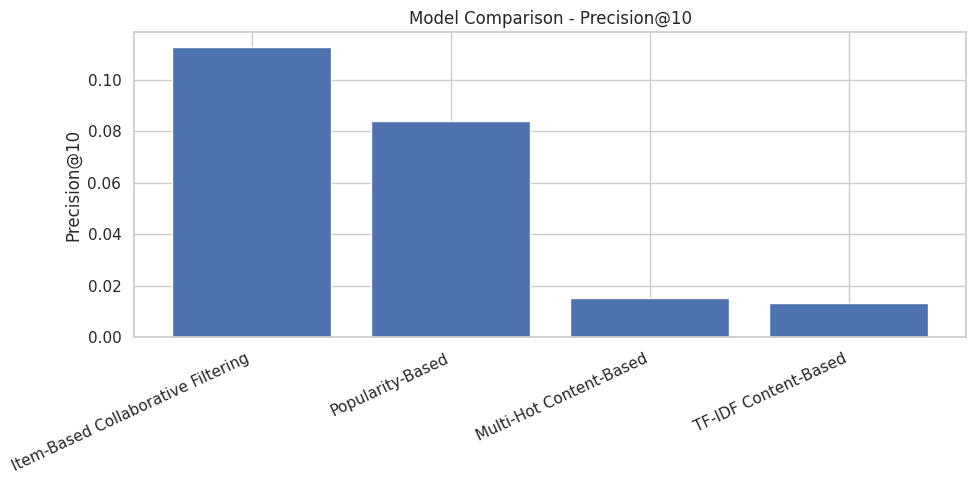

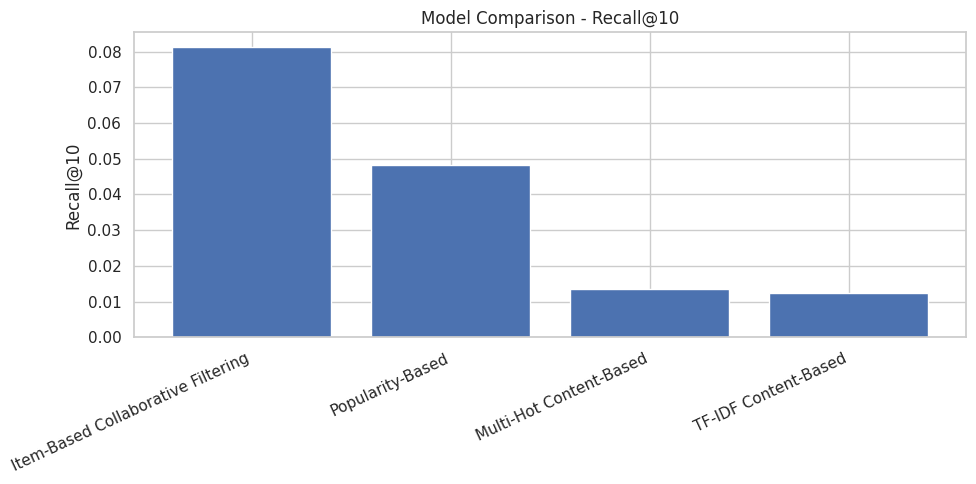

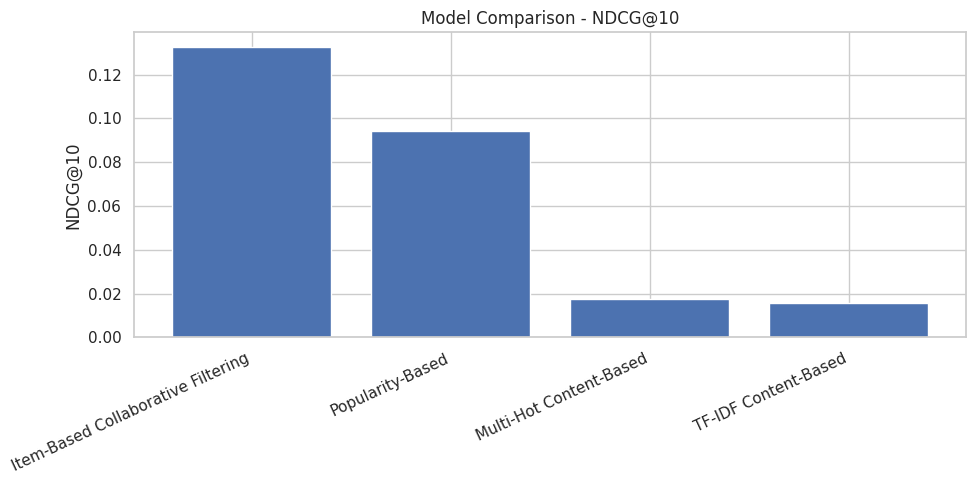

In [157]:
import matplotlib.pyplot as plt

metrics = ["Precision@10", "Recall@10", "NDCG@10"]

for metric in metrics:
    plt.figure(figsize=(10, 5))

    plt.bar(
        final_comparison["Model"],
        final_comparison[metric]
    )

    plt.title(f"Model Comparison - {metric}")
    plt.ylabel(metric)
    plt.xticks(rotation=25, ha="right")
    plt.tight_layout()
    plt.show()

## Project: Movie Recommendation System

### Objective
Build and evaluate a personalized movie recommendation system using the MovieLens 1M dataset.

### Dataset
- 1,000,209 user ratings
- 6,040 users
- 3,883 movies
- 18 movie genres

### Recommendation Approaches
1. TF-IDF Content-Based Filtering
2. Multi-Hot Content-Based Filtering
3. Popularity-Based Recommendation
4. Item-Based Collaborative Filtering
5. Hybrid Recommendation (experimental)

### Final Model
**Item-Based Collaborative Filtering**

The model calculates item-item cosine similarity using user rating patterns and generates personalized recommendations based on movies a user has rated positively.

### Final Test Results

| Metric | Score |
|---|---:|
| Precision@10 | 0.1128 |
| Recall@10 | 0.0813 |
| NDCG@10 | 0.1327 |

Evaluated on 5,987 users with relevant test ratings.

### Key Findings
- Item-Based CF outperformed all other evaluated approaches.
- It improved NDCG@10 by approximately 40.6% over the popularity baseline.
- Recommendations exclude movies already rated by the user.
- Chronological train-test splitting was used to reduce future-data leakage.
- Model selection and hybrid weight tuning were performed on a separate validation set.

### Limitations
- Genre-based content recommendations use limited metadata.
- New users and unrated movies have a cold-start problem.
- Evaluation uses historical MovieLens data and does not establish real-world user satisfaction.